In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [15]:
import json, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

try:
    from prophet import Prophet
    PROPHET_AVAILABLE = True
except Exception:
    PROPHET_AVAILABLE = False

In [16]:
DRIVE_DIR = Path("/content/drive/MyDrive")
INPUT_FILE = DRIVE_DIR / "model_ready_category_dataset.csv"
OUT_DIR = DRIVE_DIR / "model_1_rolling_origin_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEASONAL_PERIOD = 52
OUTER_ORIGINS = {
    "spring_2025": "2025-04-07",
    "summer_2025": "2025-07-07",
    "early_autumn_2025": "2025-09-08",
    "q4_year_end_2025": "2025-10-06",
}
FORECAST_HORIZONS = [4, 8, 12]

INNER_CV_HORIZON = 4
INNER_CV_OFFSETS_WEEKS = [12, 8, 4]

MOVING_AVERAGE_WINDOWS = [4, 8, 12, 26]

ETS_CONFIGS = [
    {"trend":None, "seasonal":None, "seasonal_periods":None, "label":"SES"},
    {"trend":"add", "seasonal":None, "seasonal_periods":None, "label":"Holt_Additive_Trend"},
    {"trend":None, "seasonal":"add", "seasonal_periods":52, "label":"ETS_Additive_Seasonal"},
    {"trend":"add", "seasonal":"add", "seasonal_periods":52, "label":"ETS_Additive_Trend_Seasonal"},
]

SARIMA_CONFIGS = [
    {"order":(0,1,1), "seasonal_order":(0,0,0,0), "label":"ARIMA_0_1_1"},
    {"order":(1,1,0), "seasonal_order":(0,0,0,0), "label":"ARIMA_1_1_0"},
    {"order":(1,1,1), "seasonal_order":(0,0,0,0), "label":"ARIMA_1_1_1"},
    {"order":(0,1,1), "seasonal_order":(0,1,1,52), "label":"SARIMA_0_1_1_0_1_1_52"},
    {"order":(1,1,0), "seasonal_order":(1,0,0,52), "label":"SARIMA_1_1_0_1_0_0_52"},
]

PROPHET_CONFIGS = [
    {"yearly_seasonality":True,"weekly_seasonality":False,"daily_seasonality":False,
     "seasonality_mode":"additive","changepoint_prior_scale":0.05,"seasonality_prior_scale":10.0,
     "label":"Prophet_Additive_Default"},
    {"yearly_seasonality":True,"weekly_seasonality":False,"daily_seasonality":False,
     "seasonality_mode":"multiplicative","changepoint_prior_scale":0.05,"seasonality_prior_scale":10.0,
     "label":"Prophet_Multiplicative_Default"},
    {"yearly_seasonality":True,"weekly_seasonality":False,"daily_seasonality":False,
     "seasonality_mode":"additive","changepoint_prior_scale":0.10,"seasonality_prior_scale":10.0,
     "label":"Prophet_Additive_FlexibleTrend"},
]

Shape: (6200, 3)
Categories: 40
Date range: 2023-01-09 to 2025-12-22


,scenario_id,origin_label,forecast_origin,horizon_weeks,test_start,test_end
0,spring_2025_h4,spring_2025,2025-04-07,4,2025-04-07,2025-04-28
1,spring_2025_h8,spring_2025,2025-04-07,8,2025-04-07,2025-05-26
2,spring_2025_h12,spring_2025,2025-04-07,12,2025-04-07,2025-06-23
3,summer_2025_h4,summer_2025,2025-07-07,4,2025-07-07,2025-07-28
4,summer_2025_h8,summer_2025,2025-07-07,8,2025-07-07,2025-08-25
5,summer_2025_h12,summer_2025,2025-07-07,12,2025-07-07,2025-09-22
6,early_autumn_2025_h4,early_autumn_2025,2025-09-08,4,2025-09-08,2025-09-29
7,early_autumn_2025_h8,early_autumn_2025,2025-09-08,8,2025-09-08,2025-10-27
8,early_autumn_2025_h12,early_autumn_2025,2025-09-08,12,2025-09-08,2025-11-24
9,q4_year_end_2025_h4,q4_year_end_2025,2025-10-06,4,2025-10-06,2025-10-27


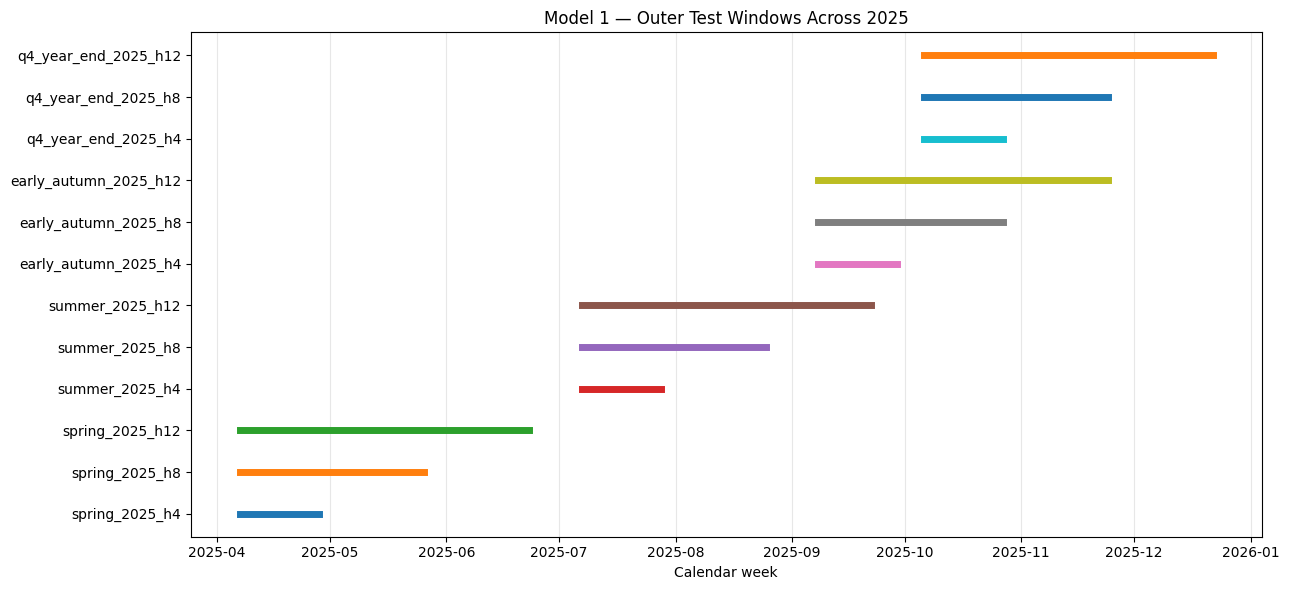

In [17]:
if not INPUT_FILE.exists():
    raise FileNotFoundError(INPUT_FILE)

raw = pd.read_csv(INPUT_FILE)
raw["week_start"] = pd.to_datetime(raw["week_start"])
required = ["Product Category","week_start","weekly_quantity"]
missing = [c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

raw = raw[required].dropna(subset=required).copy()
raw = raw.sort_values(["Product Category","week_start"])
if raw.duplicated(["Product Category","week_start"]).any():
    raise ValueError("Duplicate category-week rows found. Fix/aggregate before modelling.")

categories = sorted(raw["Product Category"].unique())
dataset_min, dataset_max = raw["week_start"].min(), raw["week_start"].max()
full_weeks = pd.date_range(dataset_min, dataset_max, freq="7D")

parts = []
for cat in categories:
    x = raw[raw["Product Category"]==cat].set_index("week_start")[["weekly_quantity"]]
    x = x.reindex(full_weeks)
    x.index.name = "week_start"
    x["weekly_quantity"] = x["weekly_quantity"].fillna(0.0)
    x["Product Category"] = cat
    parts.append(x.reset_index())
panel = pd.concat(parts, ignore_index=True).sort_values(["Product Category","week_start"])

print("Shape:", panel.shape)
print("Categories:", len(categories))
print("Date range:", dataset_min.date(), "to", dataset_max.date())

scenario_rows = []
for label, origin_s in OUTER_ORIGINS.items():
    origin = pd.Timestamp(origin_s)
    if origin not in full_weeks:
        raise ValueError(f"{origin} is not on the weekly calendar.")
    for h in FORECAST_HORIZONS:
        dates = pd.date_range(origin, periods=h, freq="7D")
        if dates[-1] > dataset_max:
            raise ValueError(f"{label}, h={h} exceeds dataset end.")
        scenario_rows.append({
            "scenario_id":f"{label}_h{h}","origin_label":label,
            "forecast_origin":origin,"horizon_weeks":h,
            "test_start":dates[0],"test_end":dates[-1]
        })
scenarios = pd.DataFrame(scenario_rows)
scenarios.to_csv(OUT_DIR/"model_1_common_rolling_origin_scenarios.csv",index=False,encoding="utf-8-sig")
display(scenarios)

plt.figure(figsize=(13,6))
for i,r in scenarios.iterrows():
    plt.plot([r.test_start,r.test_end],[i,i],linewidth=5)
plt.yticks(range(len(scenarios)),scenarios["scenario_id"])
plt.title("Model 1 — Outer Test Windows Across 2025")
plt.xlabel("Calendar week"); plt.grid(axis="x",alpha=.3); plt.tight_layout()
plt.savefig(OUT_DIR/"plot_outer_test_windows.png",dpi=160); plt.show()

In [18]:
EPS = 1e-12

def mae(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float)
    return float(np.mean(np.abs(a-p)))

def rmse(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float)
    return float(np.sqrt(np.mean((a-p)**2)))

def mape(a,p):
    # Defined only on observations with non-zero actual demand.
    a,p=np.asarray(a,float),np.asarray(p,float)
    mask=np.abs(a)>EPS
    return np.nan if mask.sum()==0 else float(np.mean(np.abs((a[mask]-p[mask])/a[mask]))*100)

def smape(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float)
    d=np.abs(a)+np.abs(p)
    return float(np.mean(np.where(d>EPS,2*np.abs(a-p)/d,0))*100)

def mase_scale_info(y_train,m=52):
    y=np.asarray(y_train,float)
    if len(y)<=m:
        return np.nan, "insufficient_history"
    diffs=np.abs(y[m:]-y[:-m])
    scale=float(np.mean(diffs))
    if not np.isfinite(scale):
        return np.nan, "non_finite_scale"
    if scale<=EPS:
        return np.nan, "zero_seasonal_scale"
    return scale, "valid"

def mase_scale(y_train,m=52):
    return mase_scale_info(y_train,m)[0]

def evaluate(a,p,y_train,m=52):
    scale,status=mase_scale_info(y_train,m)
    return {
        "MAE":mae(a,p),
        "RMSE":rmse(a,p),
        "MAPE":mape(a,p),
        "MAPE_N":int(np.sum(np.abs(np.asarray(a,float))>EPS)),
        "sMAPE":smape(a,p),
        "MASE":np.nan if not np.isfinite(scale) else mae(a,p)/scale,
        "MASE_scale":scale,
        "MASE_status":status
    }

In [19]:
def nonnegative(x):
    return np.maximum(np.asarray(x,float),0)

def seasonal_naive(train,h,m=52):
    y=np.asarray(train,float)
    if len(y)<m: return None
    return np.tile(y[-m:],int(np.ceil(h/m)))[:h]

def moving_average(train,h,w):
    y=np.asarray(train,float)
    if len(y)==0: return None
    return np.repeat(np.mean(y[-min(w,len(y)):]),h)

def ets_forecast(train,h,cfg):
    y=np.asarray(train,float)
    if cfg["seasonal_periods"] is not None and len(y)<2*cfg["seasonal_periods"]:
        return None
    try:
        fit=ExponentialSmoothing(
            y,trend=cfg["trend"],seasonal=cfg["seasonal"],
            seasonal_periods=cfg["seasonal_periods"],initialization_method="estimated"
        ).fit(optimized=True)
        return nonnegative(fit.forecast(h))
    except Exception:
        return None

def sarima_forecast(train,h,cfg):
    y=np.asarray(train,float)
    so=tuple(cfg["seasonal_order"])
    if so[-1]==52 and len(y)<104: return None
    try:
        fit=SARIMAX(
            y,order=tuple(cfg["order"]),seasonal_order=so,
            enforce_stationarity=False,enforce_invertibility=False,
            simple_differencing=False
        ).fit(disp=False,maxiter=100)
        return nonnegative(fit.forecast(h))
    except Exception:
        return None

def prophet_forecast(train_df,dates,cfg):
    if not PROPHET_AVAILABLE:
        return None

    history_days=(train_df["week_start"].max()-train_df["week_start"].min()).days
    if cfg.get("yearly_seasonality",False) and history_days < 730:
        return None

    try:
        d=train_df[["week_start","weekly_quantity"]].rename(columns={"week_start":"ds","weekly_quantity":"y"})
        model=Prophet(
            yearly_seasonality=cfg["yearly_seasonality"],
            weekly_seasonality=cfg["weekly_seasonality"],
            daily_seasonality=cfg["daily_seasonality"],
            seasonality_mode=cfg["seasonality_mode"],
            changepoint_prior_scale=cfg["changepoint_prior_scale"],
            seasonality_prior_scale=cfg["seasonality_prior_scale"]
        )
        model.fit(d)
        return nonnegative(model.predict(pd.DataFrame({"ds":pd.to_datetime(dates)}))["yhat"].values)
    except Exception:
        return None

CANDIDATES=[{"family":"SeasonalNaive","id":"seasonal_naive_52","config":{"seasonality":52}}]
CANDIDATES += [{"family":"MovingAverage","id":f"moving_average_{w}","config":{"window":w}} for w in MOVING_AVERAGE_WINDOWS]
CANDIDATES += [{"family":"ETS","id":x["label"],"config":x.copy()} for x in ETS_CONFIGS]
CANDIDATES += [{"family":"ARIMA_SARIMA","id":x["label"],"config":x.copy()} for x in SARIMA_CONFIGS]
if PROPHET_AVAILABLE:
    CANDIDATES += [{"family":"Prophet","id":x["label"],"config":x.copy()} for x in PROPHET_CONFIGS]

def forecast_candidate(candidate,train_df,dates):
    y=train_df["weekly_quantity"].values
    h=len(dates)
    if candidate["family"]=="SeasonalNaive": return seasonal_naive(y,h,52)
    if candidate["family"]=="MovingAverage": return moving_average(y,h,candidate["config"]["window"])
    if candidate["family"]=="ETS": return ets_forecast(y,h,candidate["config"])
    if candidate["family"]=="ARIMA_SARIMA": return sarima_forecast(y,h,candidate["config"])
    if candidate["family"]=="Prophet": return prophet_forecast(train_df,dates,candidate["config"])
    raise ValueError(candidate["family"])

candidate_table=pd.DataFrame([{
    "trial_id":i+1,"model_family":c["family"],"config_id":c["id"],
    "config":json.dumps(c["config"])
} for i,c in enumerate(CANDIDATES)])
candidate_table.to_csv(OUT_DIR/"model_1_candidate_configurations.csv",index=False,encoding="utf-8-sig")
print("ALL MODEL 1 CANDIDATES / HYPERPARAMETER TRIALS")
display(candidate_table)

ALL MODEL 1 CANDIDATES / HYPERPARAMETER TRIALS


,trial_id,model_family,config_id,config
0,1,SeasonalNaive,seasonal_naive_52,"{""seasonality"": 52}"
1,2,MovingAverage,moving_average_4,"{""window"": 4}"
2,3,MovingAverage,moving_average_8,"{""window"": 8}"
3,4,MovingAverage,moving_average_12,"{""window"": 12}"
4,5,MovingAverage,moving_average_26,"{""window"": 26}"
5,6,ETS,SES,"{""trend"": null, ""seasonal"": null, ""seasonal_pe..."
6,7,ETS,Holt_Additive_Trend,"{""trend"": ""add"", ""seasonal"": null, ""seasonal_p..."
7,8,ETS,ETS_Additive_Seasonal,"{""trend"": null, ""seasonal"": ""add"", ""seasonal_p..."
8,9,ETS,ETS_Additive_Trend_Seasonal,"{""trend"": ""add"", ""seasonal"": ""add"", ""seasonal_..."
9,10,ARIMA_SARIMA,ARIMA_0_1_1,"{""order"": [0, 1, 1], ""seasonal_order"": [0, 0, ..."


In [20]:
def cat_data(cat):
    return panel[panel["Product Category"]==cat].sort_values("week_start").reset_index(drop=True)

def inner_folds(outer_origin):
    folds=[]
    for k,offset in enumerate(INNER_CV_OFFSETS_WEEKS,1):
        vo=outer_origin-pd.Timedelta(weeks=offset)
        dates=pd.date_range(vo,periods=INNER_CV_HORIZON,freq="7D")
        if dates[-1]>=outer_origin:
            raise AssertionError("Inner validation overlaps outer origin.")
        folds.append((k,vo,dates))
    return folds

all_trials=[]
all_selected=[]
all_tests=[]
all_forecasts=[]

for origin_label,origin_s in OUTER_ORIGINS.items():
    origin=pd.Timestamp(origin_s)
    print("\n"+"="*90)
    print("OUTER ORIGIN:",origin_label,origin.date())
    print("="*90)

    for ci,cat in enumerate(categories,1):
        d=cat_data(cat)
        trial_rows=[]

        for fold,vo,vdates in inner_folds(origin):
            tr=d[d["week_start"]<vo].copy()
            va=d[d["week_start"].isin(vdates)].copy()

            if len(va)!=INNER_CV_HORIZON:
                raise ValueError(f"Missing validation weeks: {cat}, {origin_label}, fold {fold}")
            assert tr["week_start"].max()<va["week_start"].min()
            assert va["week_start"].max()<origin

            for trial_id,candidate in enumerate(CANDIDATES,1):
                pred=forecast_candidate(candidate,tr,va["week_start"].values)

                if pred is None:
                    row={"outer_origin_label":origin_label,"outer_origin":origin,
                         "Product Category":cat,"inner_fold":fold,"validation_origin":vo,
                         "trial_id":trial_id,"model_family":candidate["family"],
                         "config_id":candidate["id"],"config":json.dumps(candidate["config"]),
                         "status":"failed_or_ineligible",
                         "MAE":np.nan,"RMSE":np.nan,"MAPE":np.nan,"MAPE_N":0,
                         "sMAPE":np.nan,"MASE":np.nan,"MASE_scale":np.nan,
                         "MASE_status":"not_scored"}
                else:
                    met=evaluate(va["weekly_quantity"].values,pred,tr["weekly_quantity"].values,52)
                    row={"outer_origin_label":origin_label,"outer_origin":origin,
                         "Product Category":cat,"inner_fold":fold,"validation_origin":vo,
                         "trial_id":trial_id,"model_family":candidate["family"],
                         "config_id":candidate["id"],"config":json.dumps(candidate["config"]),
                         "status":"ok",**met}
                trial_rows.append(row)
                all_trials.append(row)

        tdf=pd.DataFrame(trial_rows)
        ok=tdf[tdf.status=="ok"].copy()

        summ=(ok.groupby(["trial_id","model_family","config_id","config"],as_index=False)
              .agg(cv_mean_MASE=("MASE","mean"),
                   cv_valid_MASE_folds=("MASE","count"),
                   cv_std_MASE=("MASE","std"),
                   cv_mean_sMAPE=("sMAPE","mean"),
                   cv_mean_RMSE=("RMSE","mean"),
                   cv_mean_MAE=("MAE","mean"),
                   successful_folds=("inner_fold","nunique")))

        eligible=summ[summ.successful_folds==len(INNER_CV_OFFSETS_WEEKS)].copy()
        if eligible.empty:
            raise RuntimeError(f"No candidate completed all inner folds: {cat}, {origin_label}")

        mase_eligible=eligible[eligible.cv_valid_MASE_folds==len(INNER_CV_OFFSETS_WEEKS)].copy()

        if not mase_eligible.empty:
            ranked=mase_eligible.sort_values(
                ["cv_mean_MASE","cv_std_MASE","cv_mean_RMSE","cv_mean_MAE"],
                na_position="last"
            )
            best=ranked.iloc[0]
            selection_metric="MASE"
            selection_score=float(best.cv_mean_MASE)
        else:
            ranked=eligible.sort_values(
                ["cv_mean_sMAPE","cv_mean_RMSE","cv_mean_MAE"],
                na_position="last"
            )
            best=ranked.iloc[0]
            selection_metric="sMAPE_fallback_MASE_undefined"
            selection_score=float(best.cv_mean_sMAPE)

        selected=CANDIDATES[int(best.trial_id)-1]

        all_selected.append({
            "outer_origin_label":origin_label,"outer_origin":origin,
            "Product Category":cat,"selected_model_family":selected["family"],
            "selected_config_id":selected["id"],"selected_config":json.dumps(selected["config"]),
            "selection_metric":selection_metric,"selection_score":selection_score,
            "cv_mean_MASE":best.cv_mean_MASE,"cv_valid_MASE_folds":best.cv_valid_MASE_folds,
            "cv_mean_sMAPE":best.cv_mean_sMAPE,"cv_std_MASE":best.cv_std_MASE,
            "cv_mean_RMSE":best.cv_mean_RMSE,"cv_mean_MAE":best.cv_mean_MAE
        })

        outer_train=d[d["week_start"]<origin].copy()
        assert outer_train["week_start"].max()<origin
        outer_scale,outer_scale_status=mase_scale_info(outer_train["weekly_quantity"].values,52)

        for h in FORECAST_HORIZONS:
            dates=pd.date_range(origin,periods=h,freq="7D")
            te=d[d["week_start"].isin(dates)].copy()
            if len(te)!=h:
                raise ValueError(f"Missing outer test weeks: {cat}, {origin_label}, h={h}")
            assert outer_train["week_start"].max()<te["week_start"].min()

            pred=forecast_candidate(selected,outer_train,te["week_start"].values)
            if pred is None:
                raise RuntimeError(f"Selected model failed on outer refit: {cat}, {selected['id']}")

            met=evaluate(te["weekly_quantity"].values,pred,outer_train["weekly_quantity"].values,52)
            sid=f"{origin_label}_h{h}"

            all_tests.append({
                "scenario_id":sid,"outer_origin_label":origin_label,"outer_origin":origin,
                "horizon_weeks":h,"test_start":te["week_start"].min(),"test_end":te["week_start"].max(),
                "Product Category":cat,"selected_model_family":selected["family"],
                "selected_config_id":selected["id"],"selected_config":json.dumps(selected["config"]),
                "selection_metric":selection_metric,"selection_score":selection_score,
                "cv_mean_MASE":best.cv_mean_MASE,"cv_mean_sMAPE":best.cv_mean_sMAPE,
                **met
            })

            f=te[["Product Category","week_start","weekly_quantity"]].copy()
            f["scenario_id"]=sid
            f["outer_origin_label"]=origin_label
            f["outer_origin"]=origin
            f["horizon_weeks"]=h
            f["selected_model_family"]=selected["family"]
            f["selected_config_id"]=selected["id"]
            f["y_true"]=te["weekly_quantity"].values
            f["y_pred"]=pred
            f["absolute_error"]=np.abs(f["y_true"]-f["y_pred"])
            f["MASE_status"]=outer_scale_status
            all_forecasts.append(f)

        if ci%5==0 or ci==len(categories):
            print(f"Completed {ci}/{len(categories)} categories | latest selected: {selected['id']} | selection={selection_metric}")

    pd.DataFrame(all_trials).to_csv(OUT_DIR/"model_1_inner_cv_all_trials.csv",index=False,encoding="utf-8-sig")
    pd.DataFrame(all_selected).to_csv(OUT_DIR/"model_1_selected_configurations.csv",index=False,encoding="utf-8-sig")
    pd.DataFrame(all_tests).to_csv(OUT_DIR/"model_1_outer_test_results.csv",index=False,encoding="utf-8-sig")
    pd.concat(all_forecasts,ignore_index=True).to_csv(OUT_DIR/"model_1_outer_forecasts.csv",index=False,encoding="utf-8-sig")

trials_df=pd.DataFrame(all_trials)
selected_df=pd.DataFrame(all_selected)
test_df=pd.DataFrame(all_tests)
forecasts_df=pd.concat(all_forecasts,ignore_index=True)

print("\nBACKTEST COMPLETE")
print("Outer evaluations:",len(test_df))
print("Undefined outer MASE evaluations:",test_df["MASE"].isna().sum())
display(test_df["MASE_status"].value_counts(dropna=False).rename_axis("MASE_status").reset_index(name="count"))



OUTER ORIGIN: spring_2025 2025-04-07
Completed 5/40 categories | latest selected: seasonal_naive_52 | selection=MASE
Completed 10/40 categories | latest selected: moving_average_4 | selection=MASE
Completed 15/40 categories | latest selected: ETS_Additive_Trend_Seasonal | selection=MASE
Completed 20/40 categories | latest selected: seasonal_naive_52 | selection=MASE
Completed 25/40 categories | latest selected: ARIMA_1_1_1 | selection=MASE
Completed 30/40 categories | latest selected: ETS_Additive_Seasonal | selection=MASE
Completed 35/40 categories | latest selected: seasonal_naive_52 | selection=MASE
Completed 40/40 categories | latest selected: moving_average_26 | selection=MASE

OUTER ORIGIN: summer_2025 2025-07-07
Completed 5/40 categories | latest selected: ETS_Additive_Seasonal | selection=MASE
Completed 10/40 categories | latest selected: moving_average_4 | selection=MASE
Completed 15/40 categories | latest selected: Prophet_Multiplicative_Default | selection=MASE
Completed 20

,MASE_status,count
0,valid,468
1,zero_seasonal_scale,12


In [21]:
expected=len(categories)*len(OUTER_ORIGINS)*len(FORECAST_HORIZONS)
valid_scale_mask=test_df["MASE_status"].eq("valid")

audit=pd.DataFrame([
    {"check":"Inner validation origin always precedes outer origin",
     "passed":bool((trials_df["validation_origin"]<trials_df["outer_origin"]).all())},
    {"check":"Every outer test starts exactly at its declared origin",
     "passed":bool((test_df["test_start"]==test_df["outer_origin"]).all())},
    {"check":"Expected category × origin × horizon outer evaluations",
     "passed":bool(len(test_df)==expected)},
    {"check":"Every MASE marked valid has finite positive scale",
     "passed":bool(np.isfinite(test_df.loc[valid_scale_mask,"MASE_scale"]).all()
                   and (test_df.loc[valid_scale_mask,"MASE_scale"]>0).all())},
    {"check":"Undefined MASE rows are explicitly flagged, not silently rescaled",
     "passed":bool(test_df.loc[~valid_scale_mask,"MASE"].isna().all())}
])

audit.to_csv(OUT_DIR/"model_1_leakage_audit.csv",index=False,encoding="utf-8-sig")
display(audit)

mase_undefined=(test_df[~valid_scale_mask]
                .groupby(["MASE_status","Product Category"],as_index=False)
                .size()
                .sort_values("size",ascending=False))
mase_undefined.to_csv(OUT_DIR/"model_1_undefined_mase_cases.csv",index=False,encoding="utf-8-sig")

print("Undefined MASE cases (mathematically undefined seasonal scale):")
display(mase_undefined.head(30))

if not audit.passed.all():
    raise AssertionError("Leakage/integrity audit failed.")
print("All programmed checks passed.")


,check,passed
0,Inner validation origin always precedes outer ...,True
1,Every outer test starts exactly at its declare...,True
2,Expected category × origin × horizon outer eva...,True
3,Every MASE marked valid has finite positive scale,True
4,"Undefined MASE rows are explicitly flagged, no...",True


Undefined MASE cases (mathematically undefined seasonal scale):


,MASE_status,Product Category,size
0,zero_seasonal_scale,ΠΟΡΤΟΦΟΛΙ ΜΕΣΗΣ,12


All programmed checks passed.


In [22]:
scenario_summary=(test_df.groupby(
    ["scenario_id","outer_origin_label","outer_origin","horizon_weeks"],as_index=False)
    .agg(mean_MAE=("MAE","mean"),mean_RMSE=("RMSE","mean"),
         mean_MAPE=("MAPE","mean"),mean_sMAPE=("sMAPE","mean"),
         mean_MASE=("MASE","mean"),median_MASE=("MASE","median"),
         std_MASE=("MASE","std"),valid_MASE_N=("MASE","count"),
         total_categories=("Product Category","nunique")))

overall=pd.DataFrame([{
    "Model":"Model 1 - Statistical Benchmark",
    "mean_MAE":test_df.MAE.mean(),
    "mean_RMSE":test_df.RMSE.mean(),
    "mean_MAPE":test_df.MAPE.mean(),
    "mean_sMAPE":test_df.sMAPE.mean(),
    "mean_MASE":test_df.MASE.mean(),
    "median_MASE":test_df.MASE.median(),
    "valid_MASE_evaluations":int(test_df.MASE.notna().sum()),
    "undefined_MASE_evaluations":int(test_df.MASE.isna().sum()),
    "n_outer_evaluations":len(test_df)
}])

scenario_summary.to_csv(OUT_DIR/"model_1_scenario_summary.csv",index=False,encoding="utf-8-sig")
overall.to_csv(OUT_DIR/"model_1_overall_summary.csv",index=False,encoding="utf-8-sig")
display(scenario_summary)
display(overall)

,scenario_id,outer_origin_label,outer_origin,horizon_weeks,mean_MAE,mean_RMSE,mean_MAPE,mean_sMAPE,mean_MASE,median_MASE,std_MASE,valid_MASE_N,total_categories
0,early_autumn_2025_h12,early_autumn_2025,2025-09-08,12,82.413420,106.175525,243.711668,79.963443,1.413853,0.569126,1.897785,39,40
1,early_autumn_2025_h4,early_autumn_2025,2025-09-08,4,114.273325,134.266581,72.322718,80.589350,2.216187,0.788529,3.579361,39,40
2,early_autumn_2025_h8,early_autumn_2025,2025-09-08,8,98.906593,120.618065,92.803371,73.662594,1.712905,0.756438,2.384353,39,40
3,q4_year_end_2025_h12,q4_year_end_2025,2025-10-06,12,63.640188,74.157990,488.830151,84.593270,0.864698,0.460385,1.149324,39,40
4,q4_year_end_2025_h4,q4_year_end_2025,2025-10-06,4,75.931371,82.371943,115.855069,51.453242,0.822769,0.505804,0.967773,39,40
5,q4_year_end_2025_h8,q4_year_end_2025,2025-10-06,8,73.926902,81.911904,452.778327,76.437906,0.919459,0.573678,1.159071,39,40
6,spring_2025_h12,spring_2025,2025-04-07,12,79.891476,97.620892,239.767424,76.150466,0.873910,0.560732,0.947887,39,40
7,spring_2025_h4,spring_2025,2025-04-07,4,86.813798,104.618732,96.272608,56.766841,0.949661,0.624982,1.050952,39,40
8,spring_2025_h8,spring_2025,2025-04-07,8,80.734951,99.347766,113.725065,68.184674,0.907376,0.533370,0.966884,39,40
9,summer_2025_h12,summer_2025,2025-07-07,12,60.937117,92.271821,165.572276,112.805038,1.002454,0.508718,1.307057,39,40


,Model,mean_MAE,mean_RMSE,mean_MAPE,mean_sMAPE,mean_MASE,median_MASE,valid_MASE_evaluations,undefined_MASE_evaluations,n_outer_evaluations
0,Model 1 - Statistical Benchmark,72.885009,88.827605,215.011254,81.804379,1.031349,0.468898,468,12,480


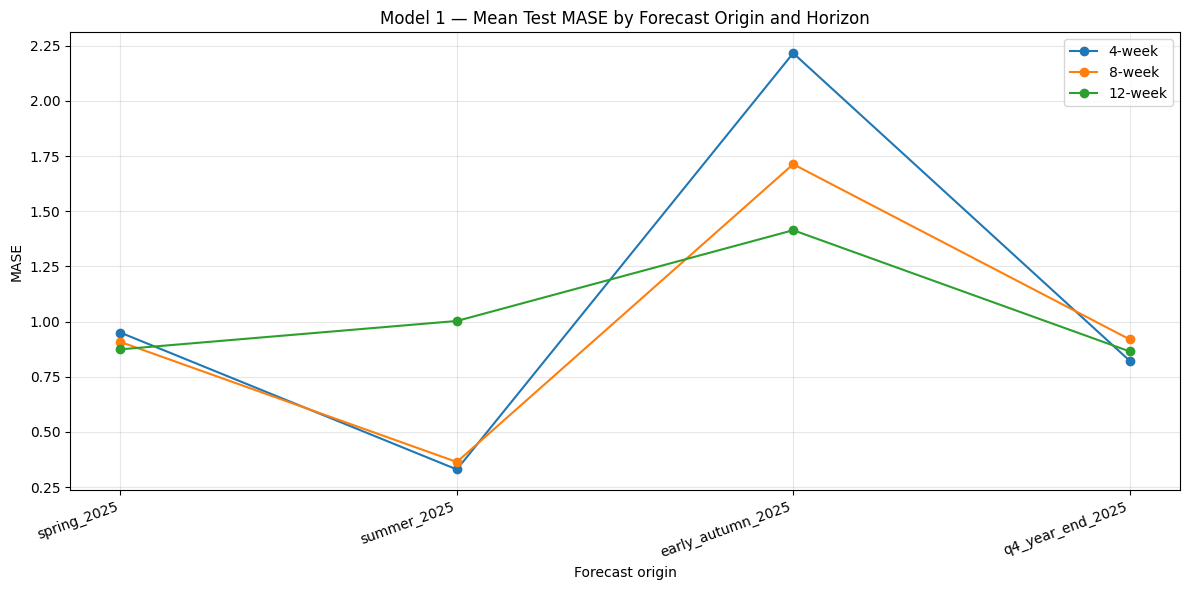

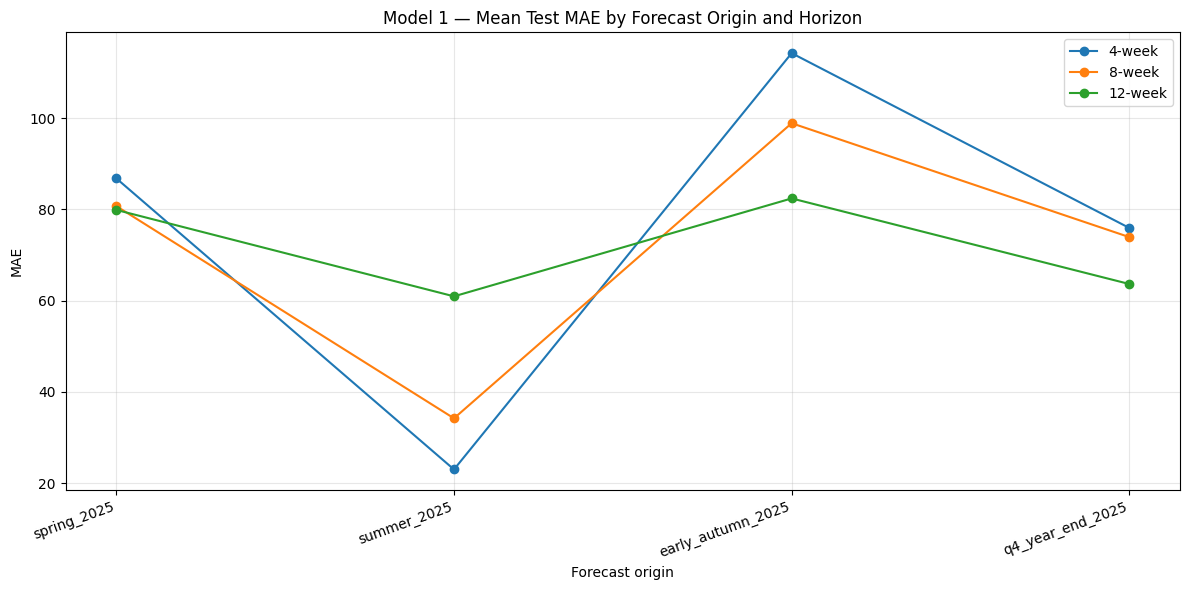

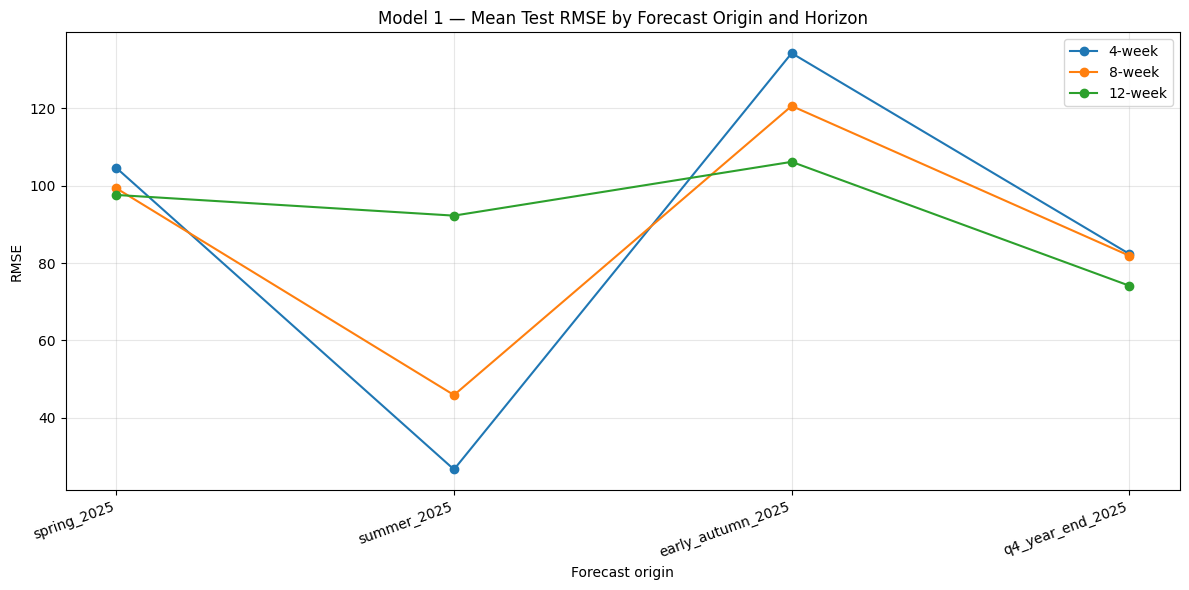

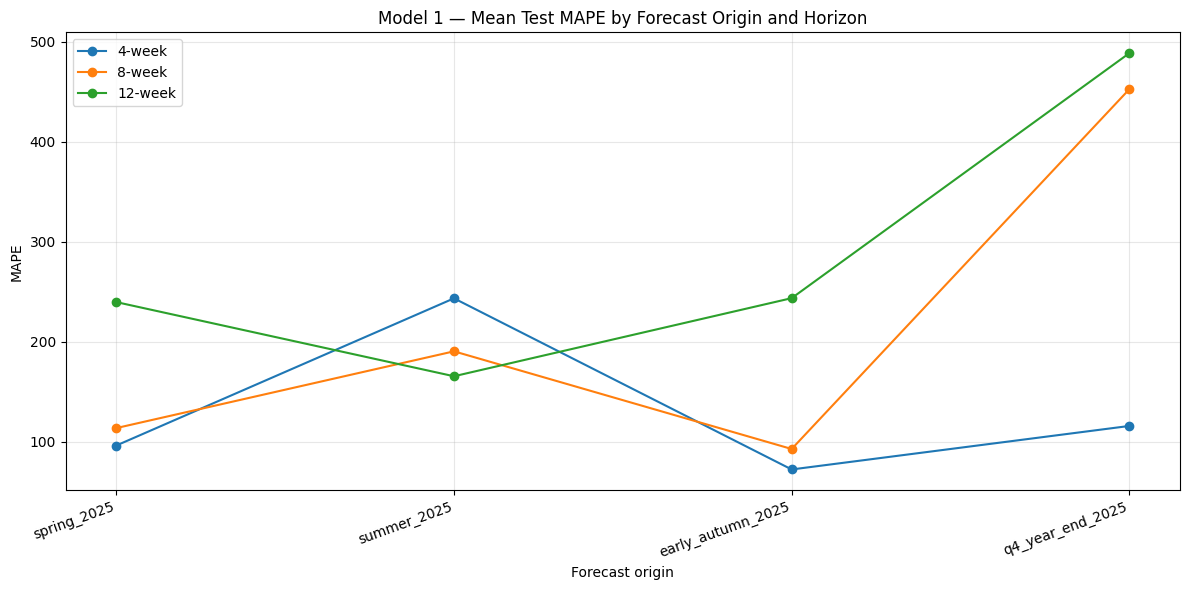

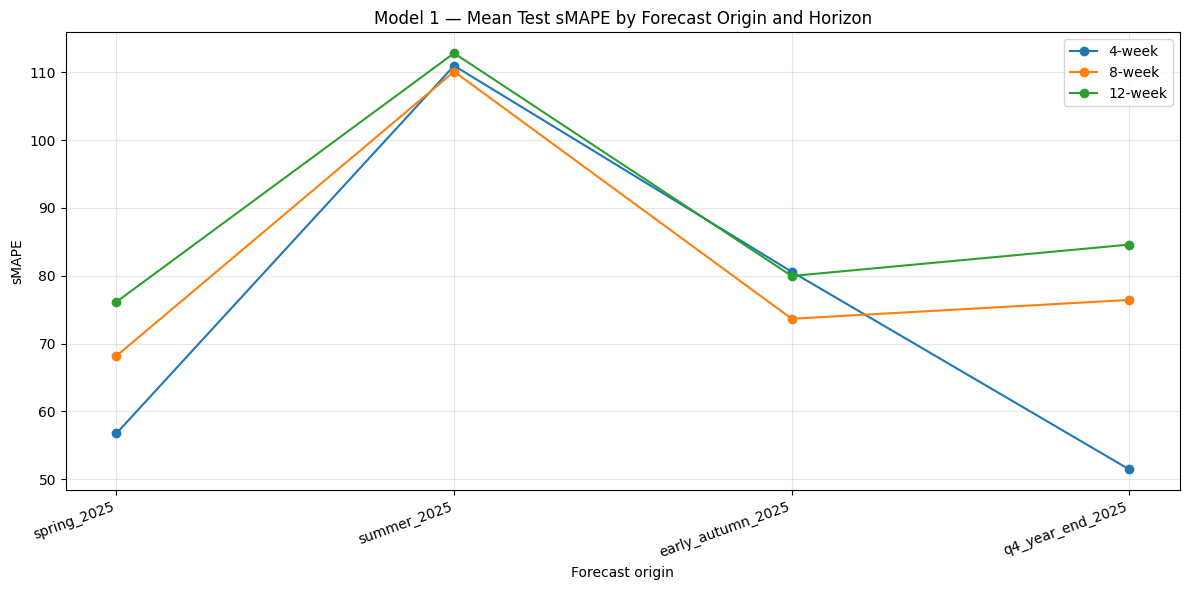

In [23]:
origin_order=list(OUTER_ORIGINS.keys())

def metric_plot(metric):
    z=(test_df.groupby(["outer_origin_label","horizon_weeks"],as_index=False)[metric].mean())
    z["outer_origin_label"]=pd.Categorical(z["outer_origin_label"],origin_order,ordered=True)
    z=z.sort_values(["outer_origin_label","horizon_weeks"])
    plt.figure(figsize=(12,6))
    for h in FORECAST_HORIZONS:
        q=z[z.horizon_weeks==h]
        plt.plot(q["outer_origin_label"].astype(str),q[metric],marker="o",label=f"{h}-week")
    plt.title(f"Model 1 — Mean Test {metric} by Forecast Origin and Horizon")
    plt.xlabel("Forecast origin"); plt.ylabel(metric); plt.legend()
    plt.grid(alpha=.3); plt.xticks(rotation=20,ha="right"); plt.tight_layout()
    plt.savefig(OUT_DIR/f"plot_{metric.lower()}_by_origin_horizon.png",dpi=160); plt.show()

for metric in ["MASE","MAE","RMSE","MAPE","sMAPE"]:
    metric_plot(metric)

,trial_id,model_family,config_id,mean_inner_MASE,std_inner_MASE,runs
10,11,ARIMA_SARIMA,ARIMA_1_1_0,0.814036,2.706001,468
13,14,ARIMA_SARIMA,SARIMA_1_1_0_1_0_0_52,0.824393,2.724811,468
9,10,ARIMA_SARIMA,ARIMA_0_1_1,0.854801,2.727967,468
1,2,MovingAverage,moving_average_4,0.872978,2.799496,468
6,7,ETS,Holt_Additive_Trend,0.879304,2.719476,468
5,6,ETS,SES,0.893239,2.720088,468
12,13,ARIMA_SARIMA,SARIMA_0_1_1_0_1_1_52,0.907468,2.661182,468
7,8,ETS,ETS_Additive_Seasonal,0.930247,2.772589,468
11,12,ARIMA_SARIMA,ARIMA_1_1_1,0.932227,2.701796,468
15,16,Prophet,Prophet_Multiplicative_Default,0.943660,2.804127,429


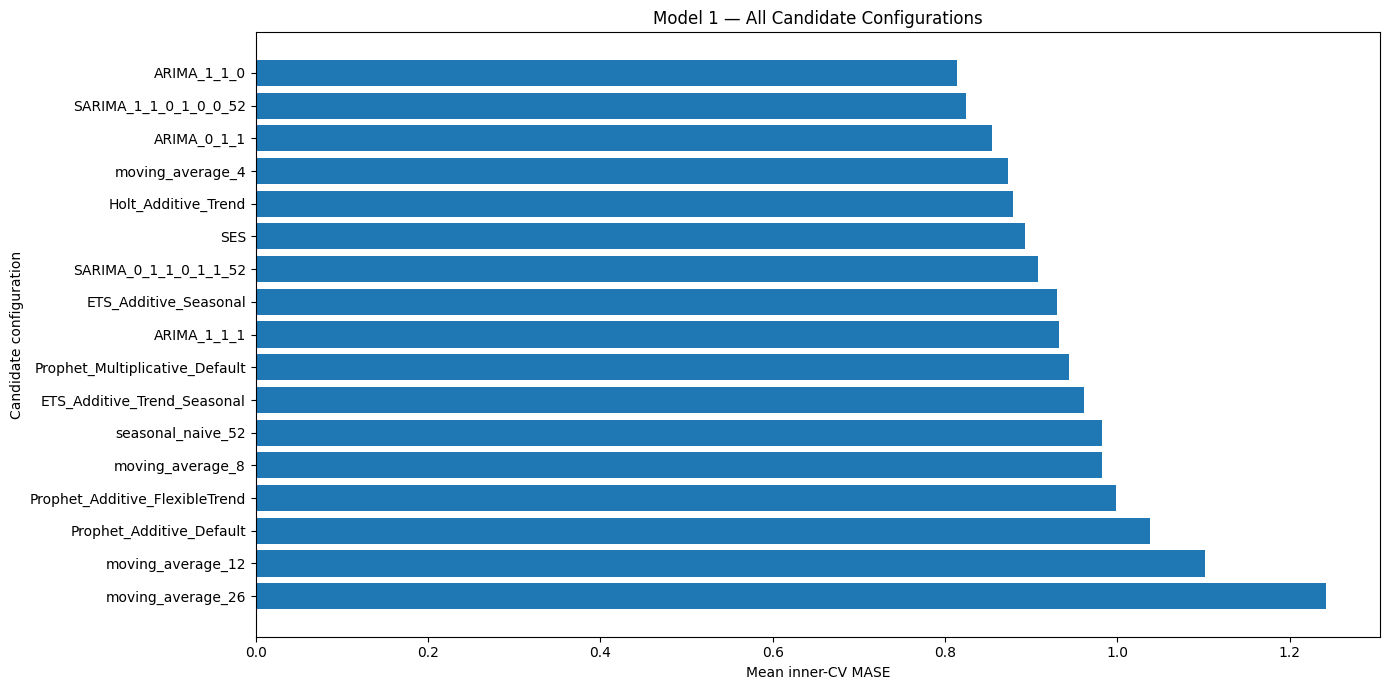

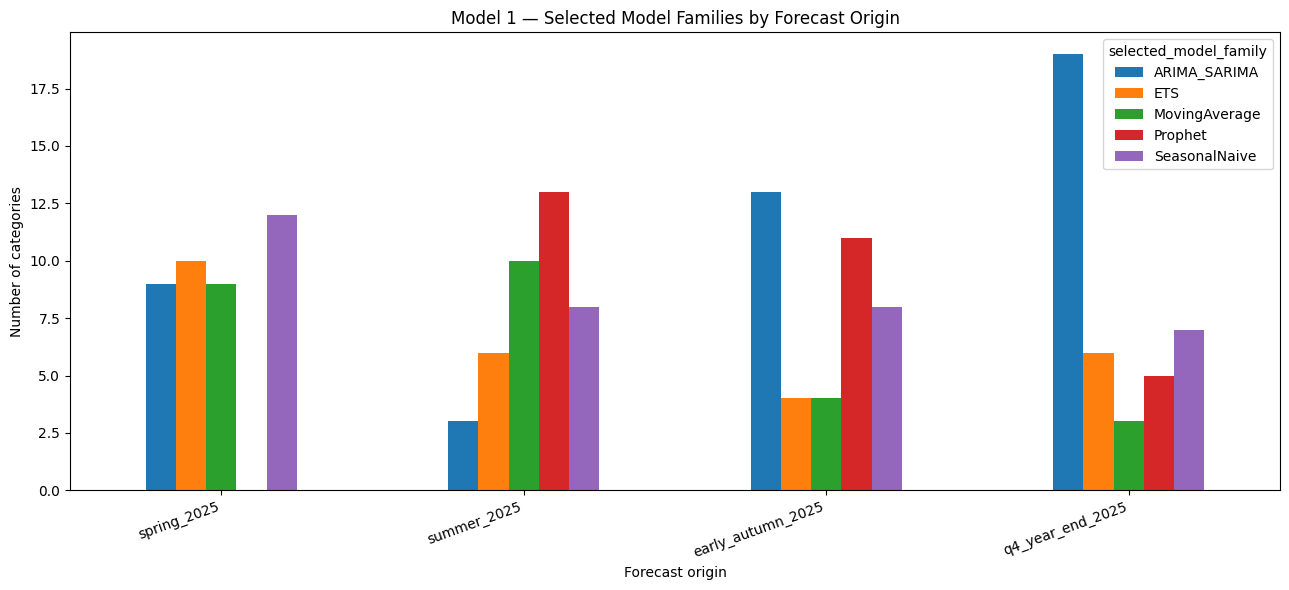

In [24]:
trial_perf=(trials_df[trials_df.status=="ok"]
    .groupby(["trial_id","model_family","config_id"],as_index=False)
    .agg(mean_inner_MASE=("MASE","mean"),std_inner_MASE=("MASE","std"),
         runs=("MASE","count"))
    .sort_values("mean_inner_MASE"))
trial_perf.to_csv(OUT_DIR/"model_1_all_candidate_performance.csv",index=False,encoding="utf-8-sig")
display(trial_perf)

plt.figure(figsize=(14,7))
plt.barh(trial_perf.config_id.astype(str),trial_perf.mean_inner_MASE)
plt.xlabel("Mean inner-CV MASE"); plt.ylabel("Candidate configuration")
plt.title("Model 1 — All Candidate Configurations")
plt.gca().invert_yaxis(); plt.tight_layout()
plt.savefig(OUT_DIR/"plot_all_candidate_cv_mase.png",dpi=160); plt.show()

counts=(selected_df.groupby(["outer_origin_label","selected_model_family"],as_index=False)
        .agg(selected_count=("Product Category","count")))
pivot=counts.pivot_table(index="outer_origin_label",columns="selected_model_family",
                         values="selected_count",fill_value=0).reindex(origin_order)
pivot.plot(kind="bar",figsize=(13,6))
plt.title("Model 1 — Selected Model Families by Forecast Origin")
plt.ylabel("Number of categories"); plt.xlabel("Forecast origin")
plt.xticks(rotation=20,ha="right"); plt.tight_layout()
plt.savefig(OUT_DIR/"plot_selected_model_families.png",dpi=160); plt.show()

,outer_origin_label,horizon_weeks,mean_cv_MASE,mean_test_MASE,mean_gap,median_test_to_cv_ratio,valid_pairs
0,early_autumn_2025,4,0.295494,2.216187,1.920693,4.226686,39
1,early_autumn_2025,8,0.295494,1.712905,1.417411,3.912792,39
2,early_autumn_2025,12,0.295494,1.413853,1.118360,2.931031,39
3,q4_year_end_2025,4,0.789592,0.822769,0.033177,1.104117,39
4,q4_year_end_2025,8,0.789592,0.919459,0.129868,1.239266,39
5,q4_year_end_2025,12,0.789592,0.864698,0.075106,1.138253,39
6,spring_2025,4,0.943976,0.949661,0.005685,1.441466,39
7,spring_2025,8,0.943976,0.907376,-0.036600,1.729000,39
8,spring_2025,12,0.943976,0.873910,-0.070066,1.624381,39
9,summer_2025,4,0.447820,0.329564,-0.118256,0.759295,39


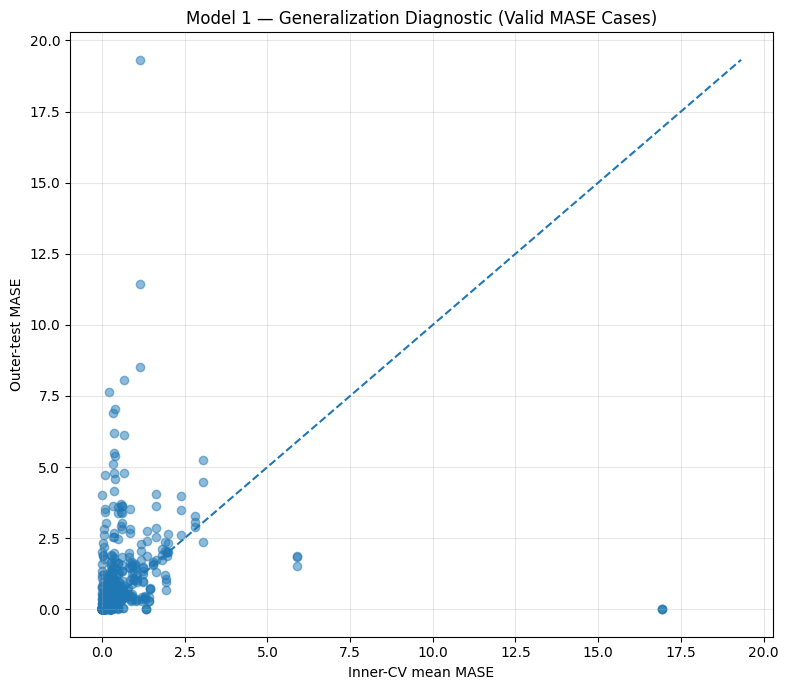

In [25]:
stability=test_df.copy()
stability["test_minus_cv_MASE"]=stability.MASE-stability.cv_mean_MASE
stability["test_to_cv_ratio"]=stability.MASE/stability.cv_mean_MASE.replace(0,np.nan)

stab_summary=(stability.groupby(["outer_origin_label","horizon_weeks"],as_index=False)
              .agg(mean_cv_MASE=("cv_mean_MASE","mean"),
                   mean_test_MASE=("MASE","mean"),
                   mean_gap=("test_minus_cv_MASE","mean"),
                   median_test_to_cv_ratio=("test_to_cv_ratio","median"),
                   valid_pairs=("test_minus_cv_MASE","count")))
stab_summary.to_csv(OUT_DIR/"model_1_cv_test_stability.csv",index=False,encoding="utf-8-sig")
display(stab_summary)

plot_stability=stability[
    np.isfinite(stability["cv_mean_MASE"]) & np.isfinite(stability["MASE"])
].copy()

if len(plot_stability):
    plt.figure(figsize=(8,7))
    plt.scatter(plot_stability.cv_mean_MASE,plot_stability.MASE,alpha=.5)
    mx=np.nanmax([plot_stability.cv_mean_MASE.max(),plot_stability.MASE.max()])
    plt.plot([0,mx],[0,mx],linestyle="--")
    plt.xlabel("Inner-CV mean MASE"); plt.ylabel("Outer-test MASE")
    plt.title("Model 1 — Generalization Diagnostic (Valid MASE Cases)")
    plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(OUT_DIR/"plot_cv_vs_test_mase.png",dpi=160); plt.show()
else:
    print("No finite CV/test MASE pairs available for this diagnostic.")

,Product Category,mean_MAE,mean_RMSE,mean_MAPE,mean_sMAPE,mean_MASE,std_MASE
3,ΓΑΝΤΙ ΑΝΔΡΙΚΟ,10.473039,14.349079,84.383308,88.006912,4.530158,6.030060
5,ΓΟΥΝΑ,23.991509,29.125129,162.818472,67.332768,2.936526,2.777977
11,ΚAΣΚΟΛ,434.919040,510.987560,644.376124,96.312854,2.458342,2.290185
30,ΣΚΟΥΦΟΣ ΑΝΔΡΙΚΟΣ,32.001339,45.475671,299.927650,84.150288,2.292281,1.609036
4,ΓΑΝΤΙ ΓΥΝΑΙΚΕΙΟ,119.931902,137.587290,301.816200,101.533357,2.132873,2.366762
13,ΚΑΣΚΟΛ ΑΝΔΡΙΚΟ,131.862628,167.651672,297.634471,88.365505,2.093057,2.235738
2,ΑΝΔΡΙΚΗ ΤΣΑΝΤΑ,35.972110,40.856271,304.200276,106.458711,1.821977,1.032749
6,ΕΣΑΡΠΑ,346.272471,404.984858,672.735328,122.653222,1.649064,0.967045
28,ΣΑΚΟΥΛΑ,24.928084,28.043377,241.326024,163.014105,1.615370,1.197197
12,ΚΑΠΑ,38.204752,52.169401,81.360997,73.810264,1.448877,1.351944


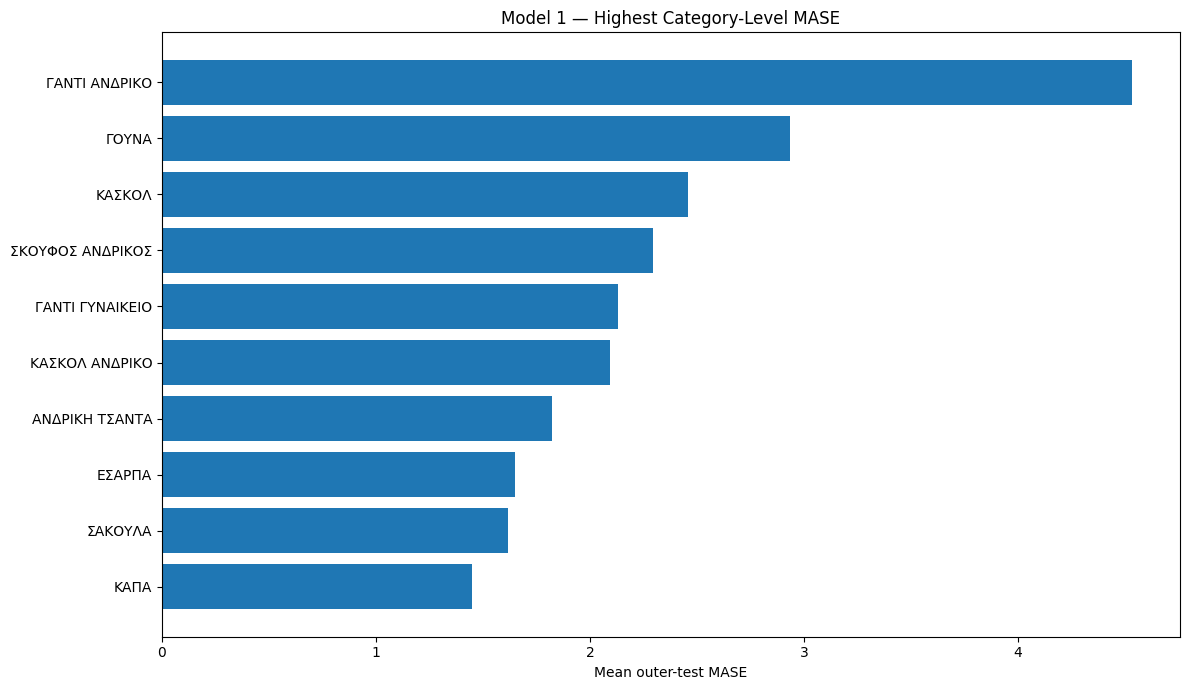

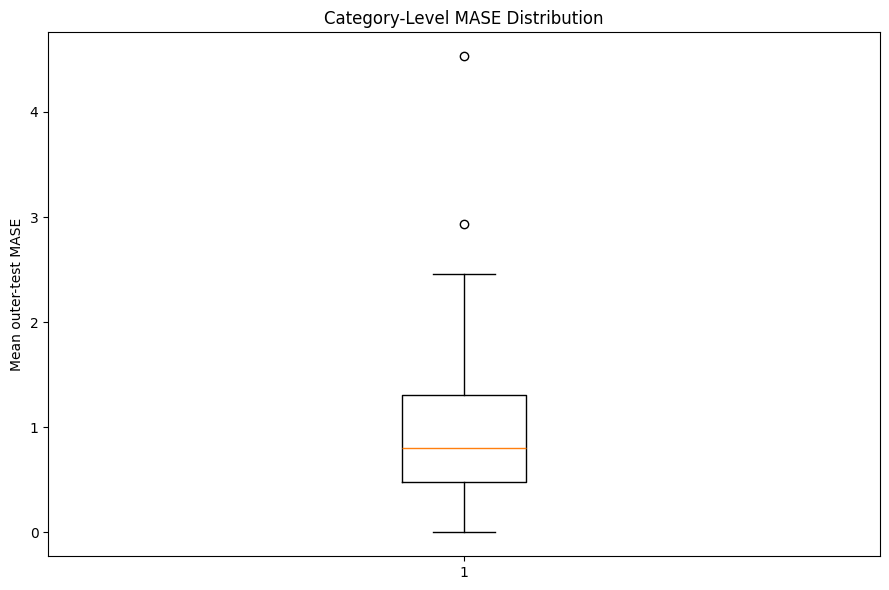

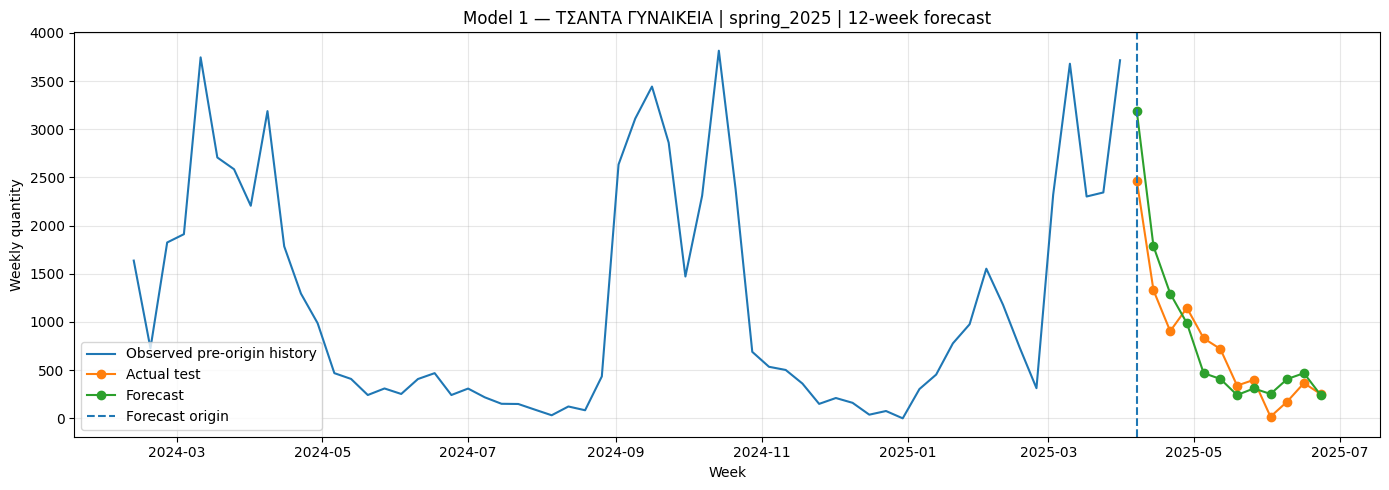

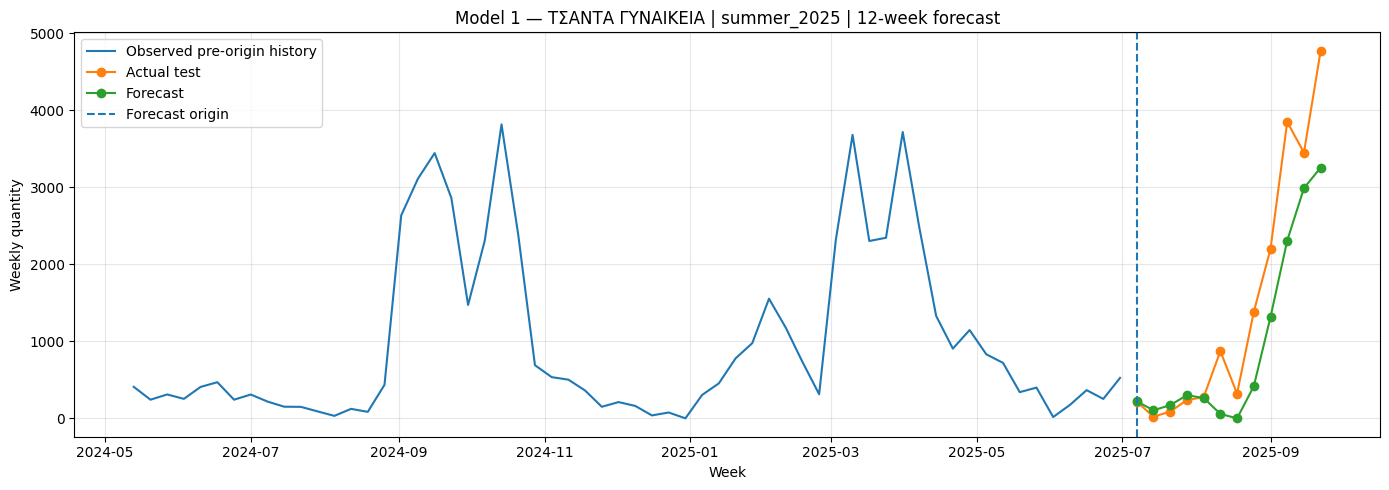

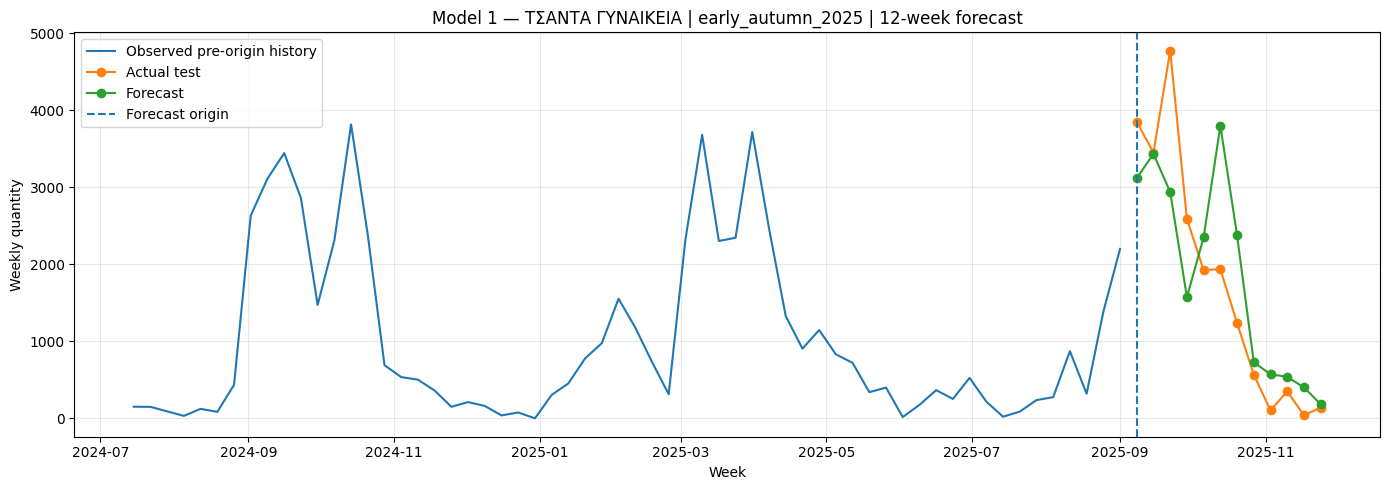

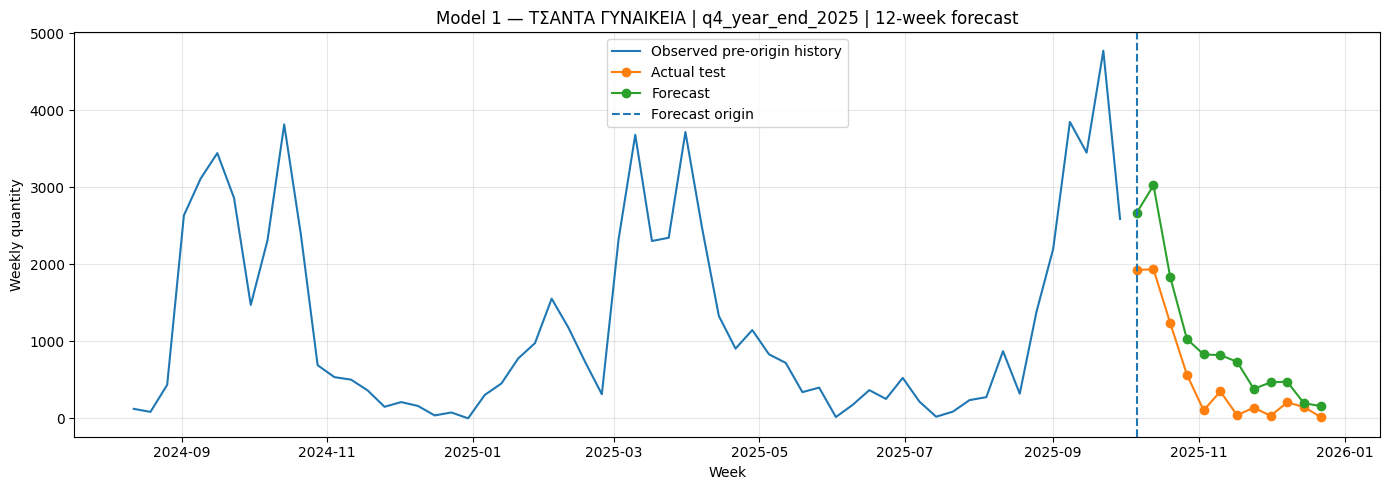

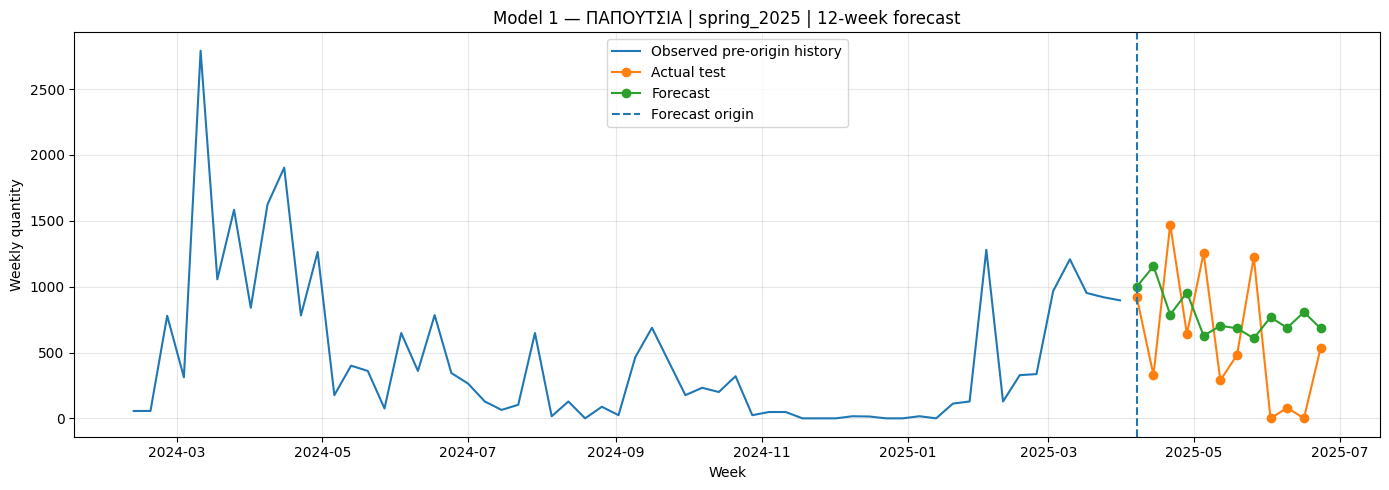

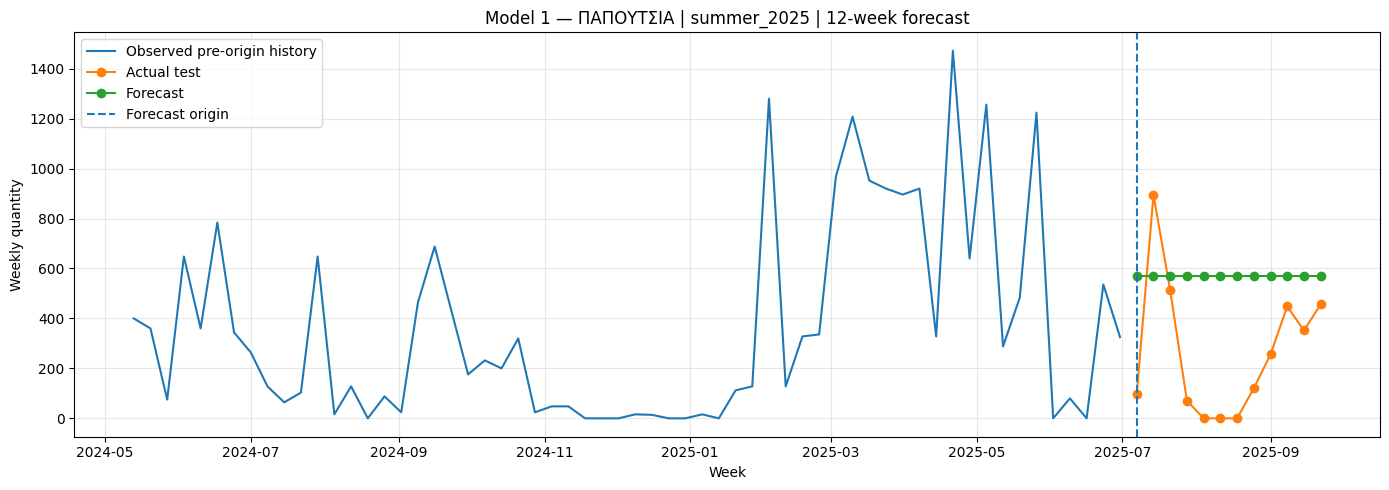

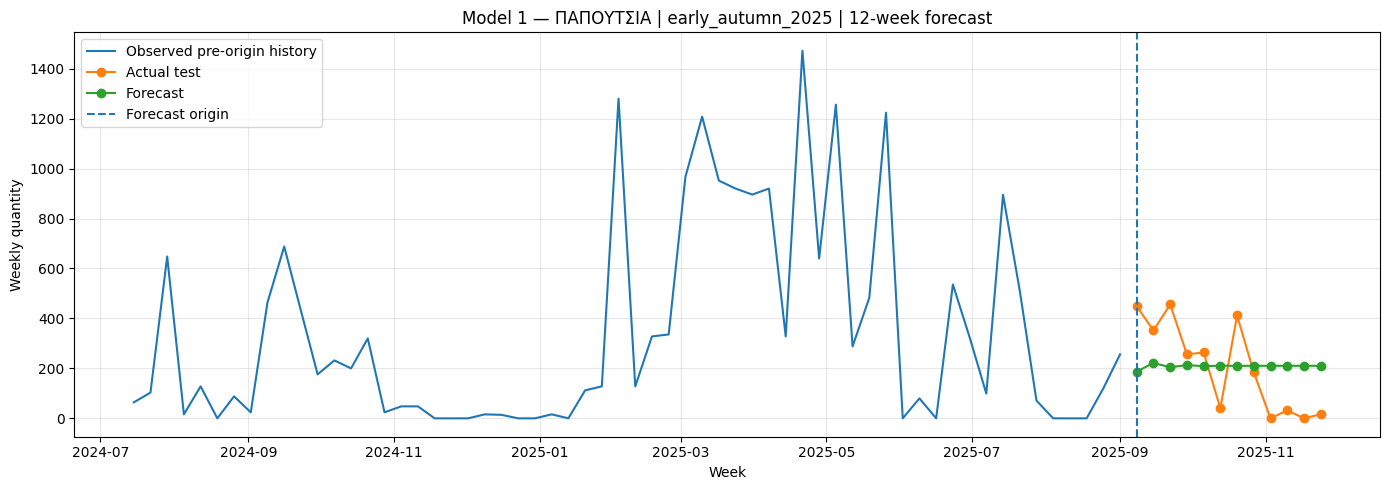

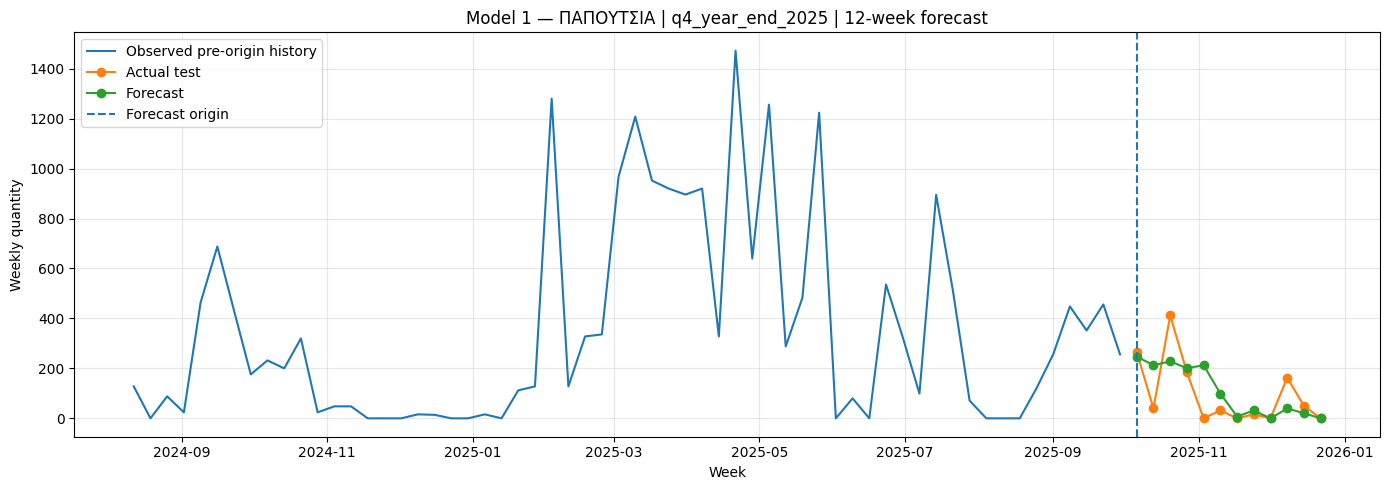

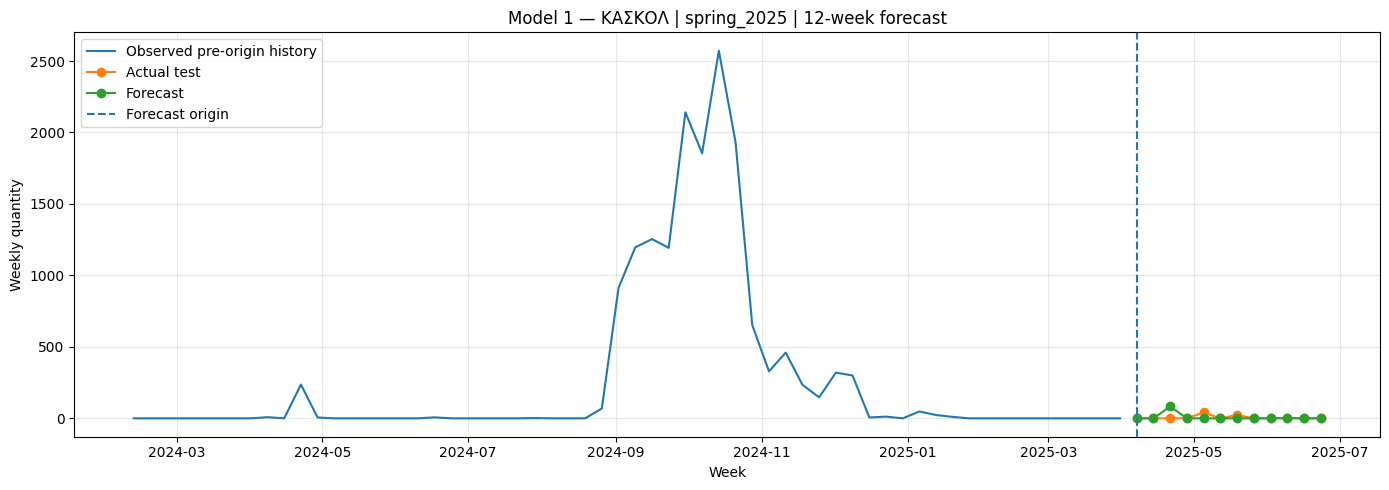

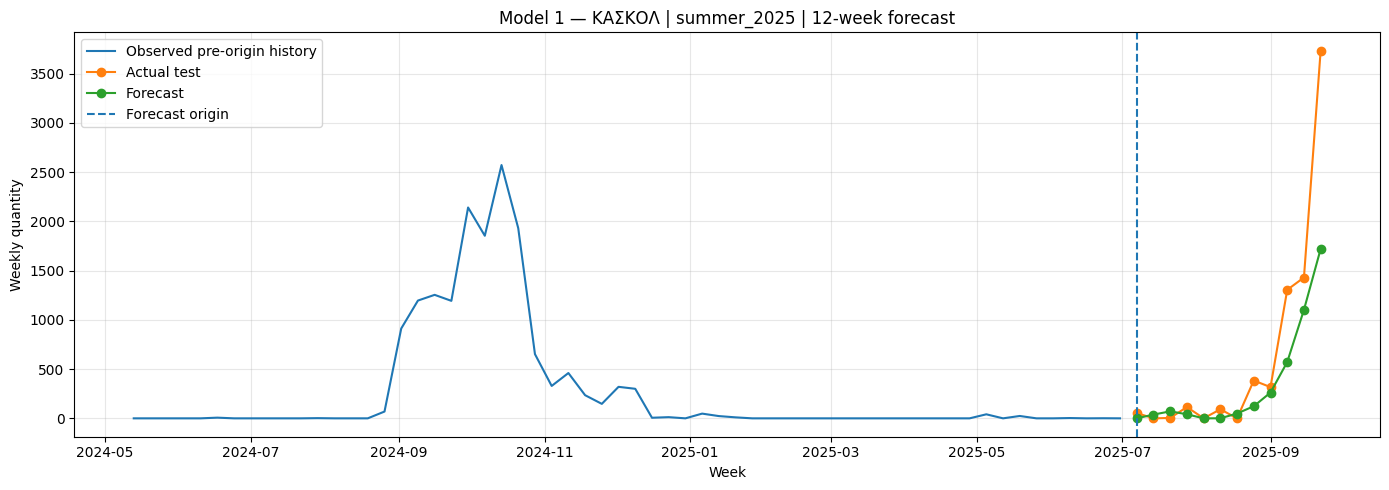

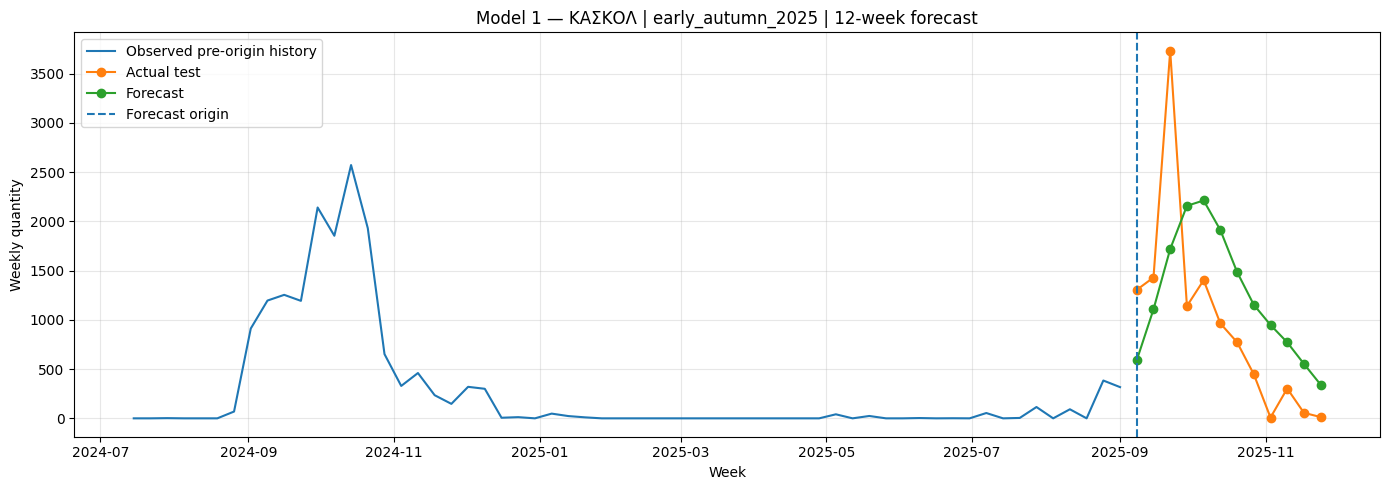

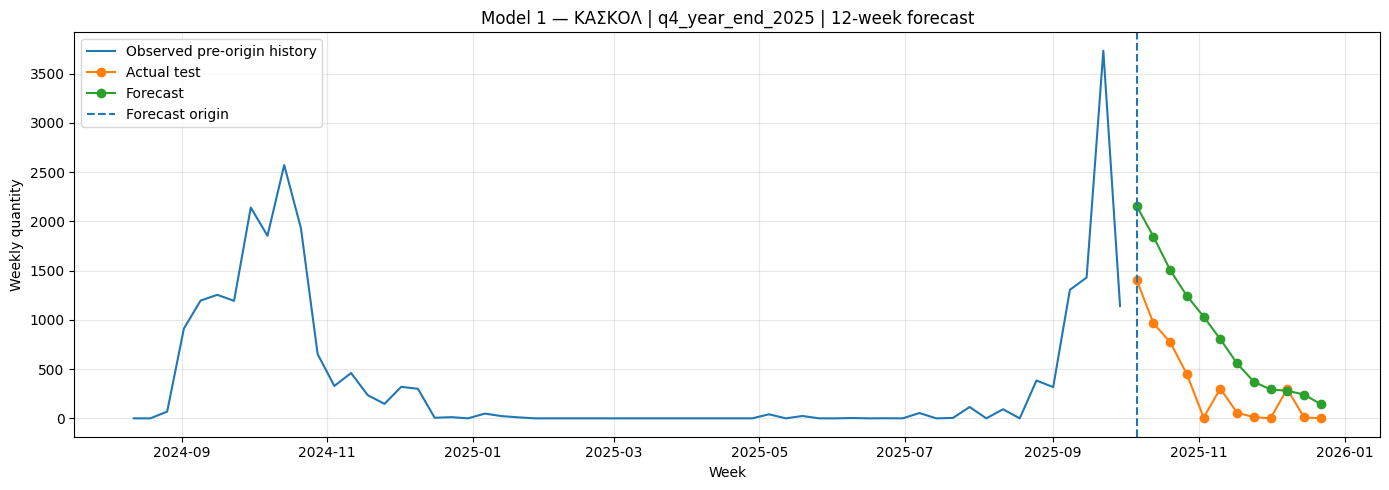

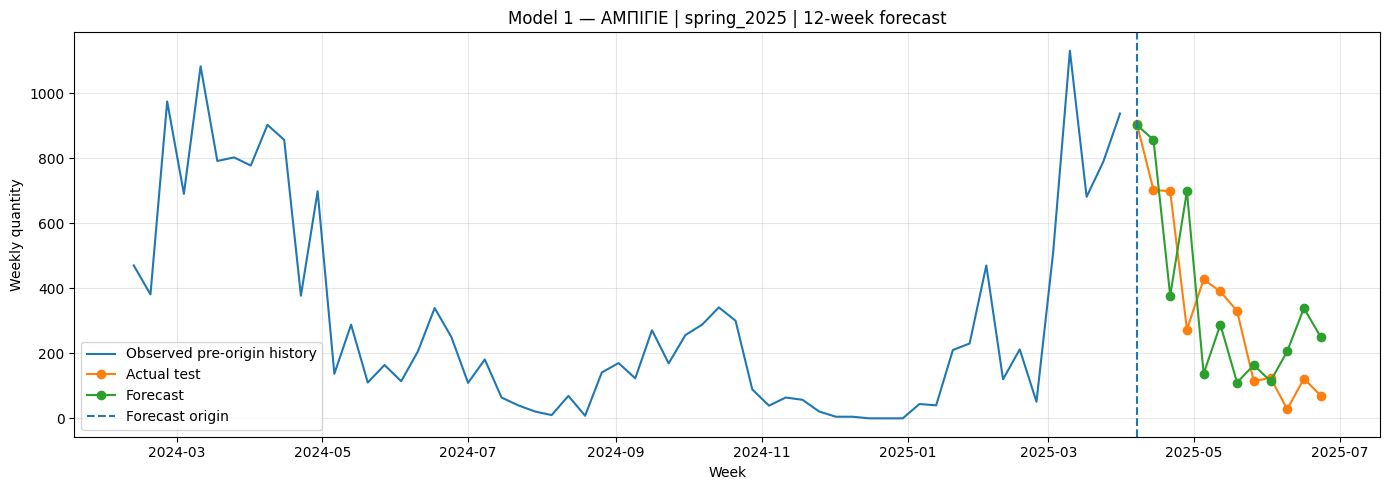

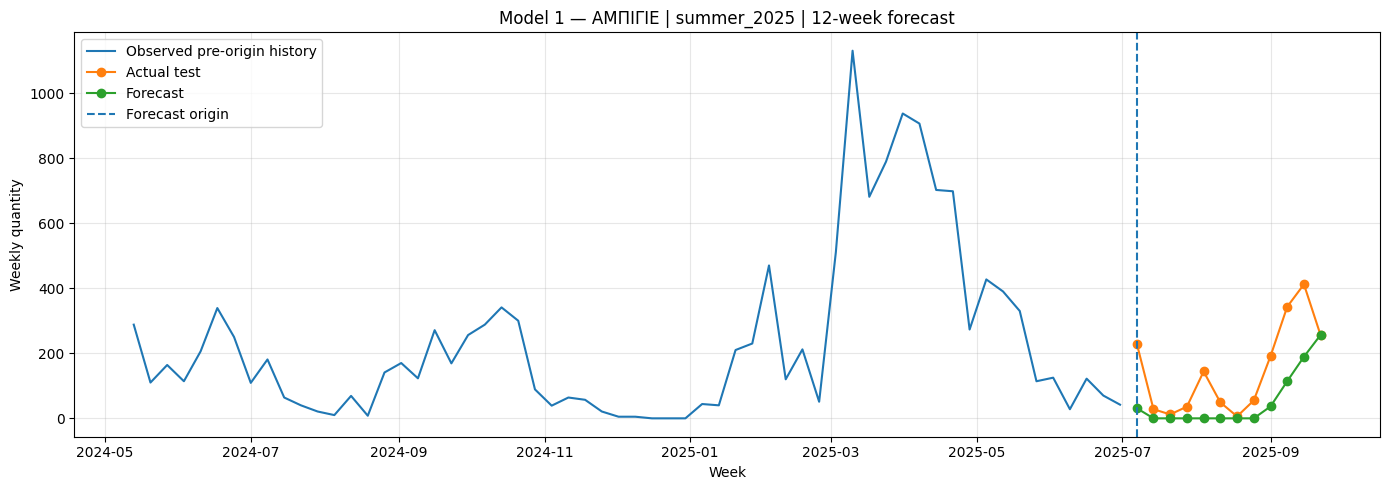

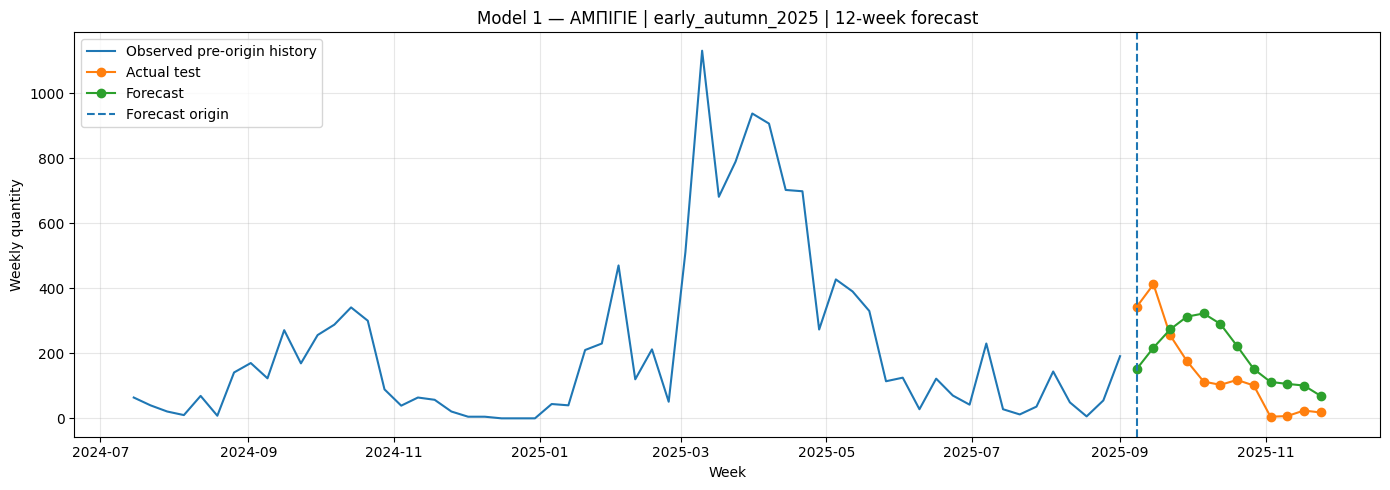

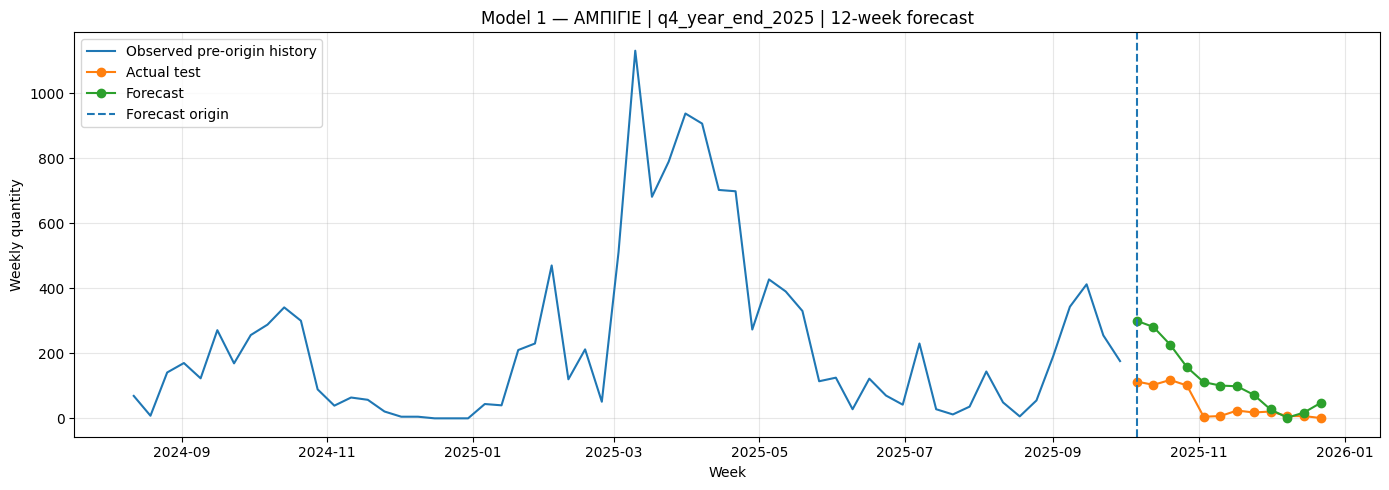

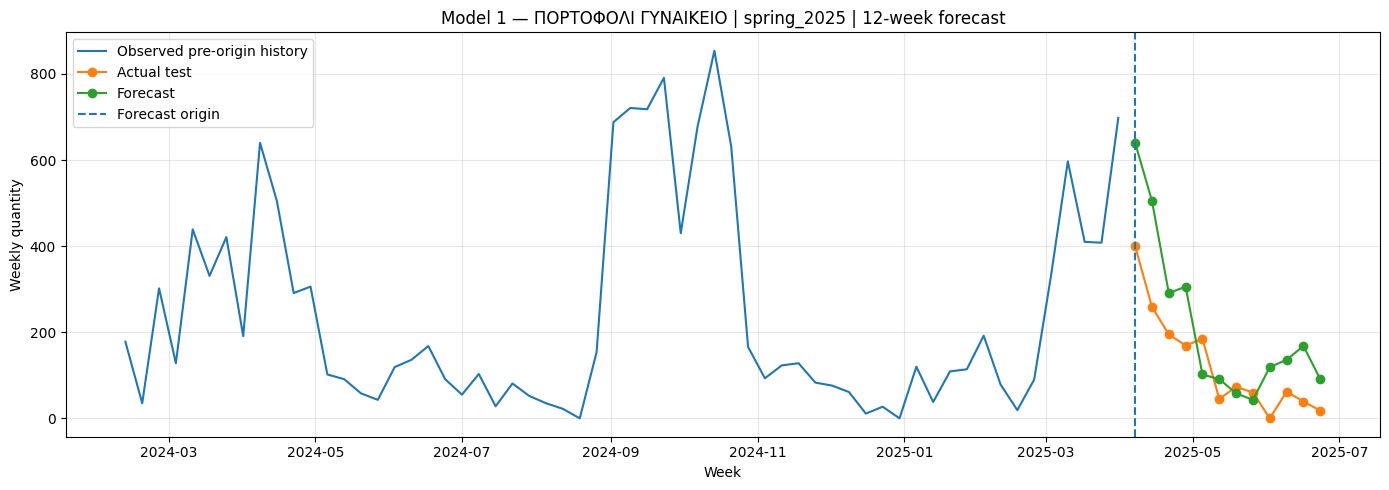

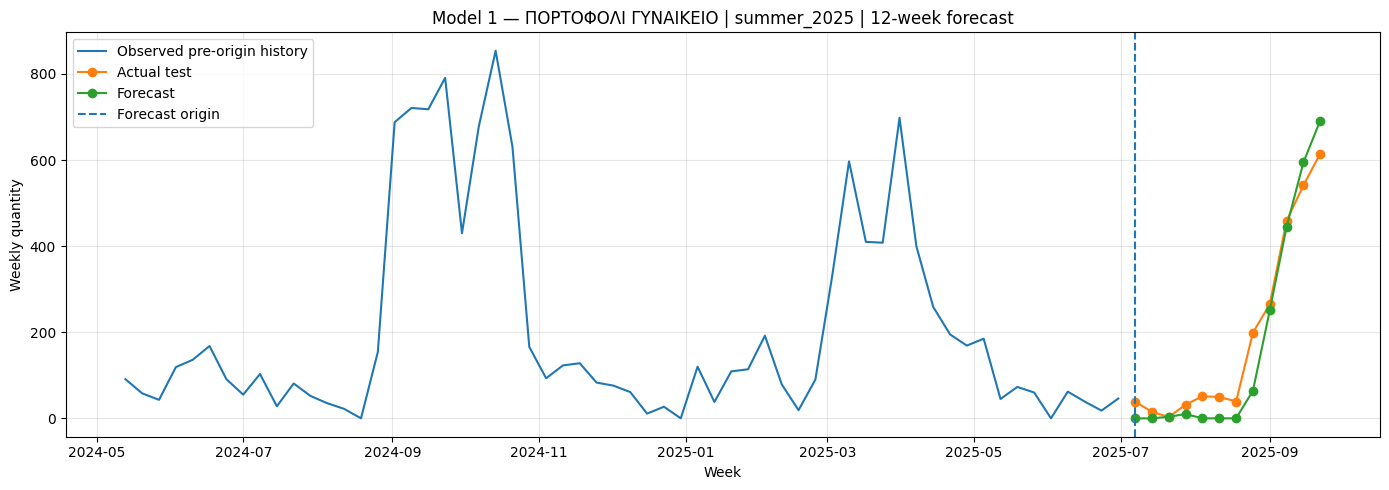

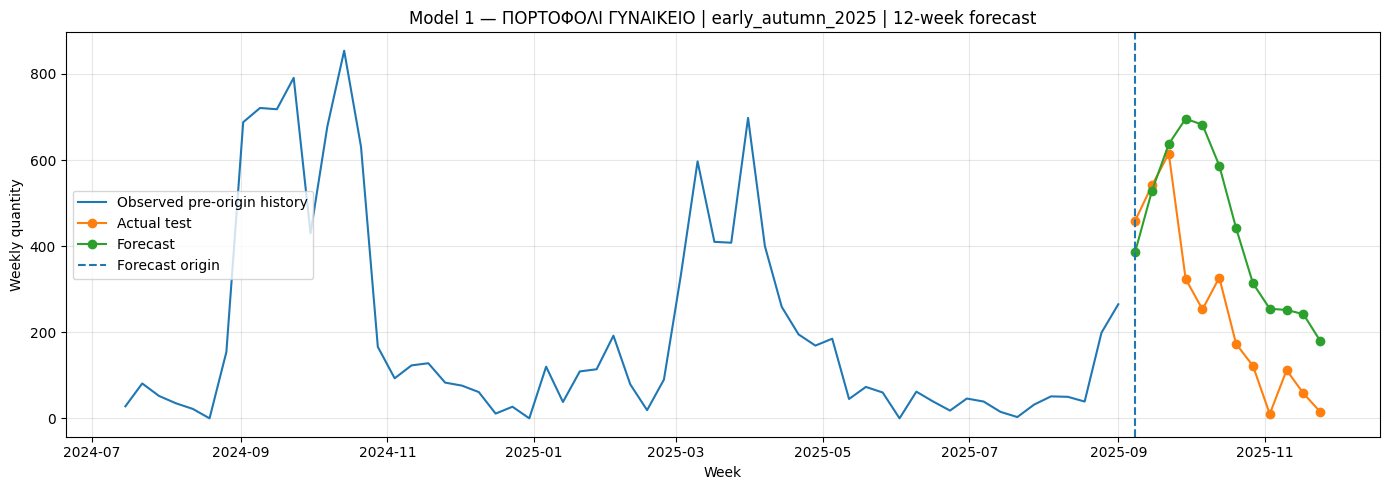

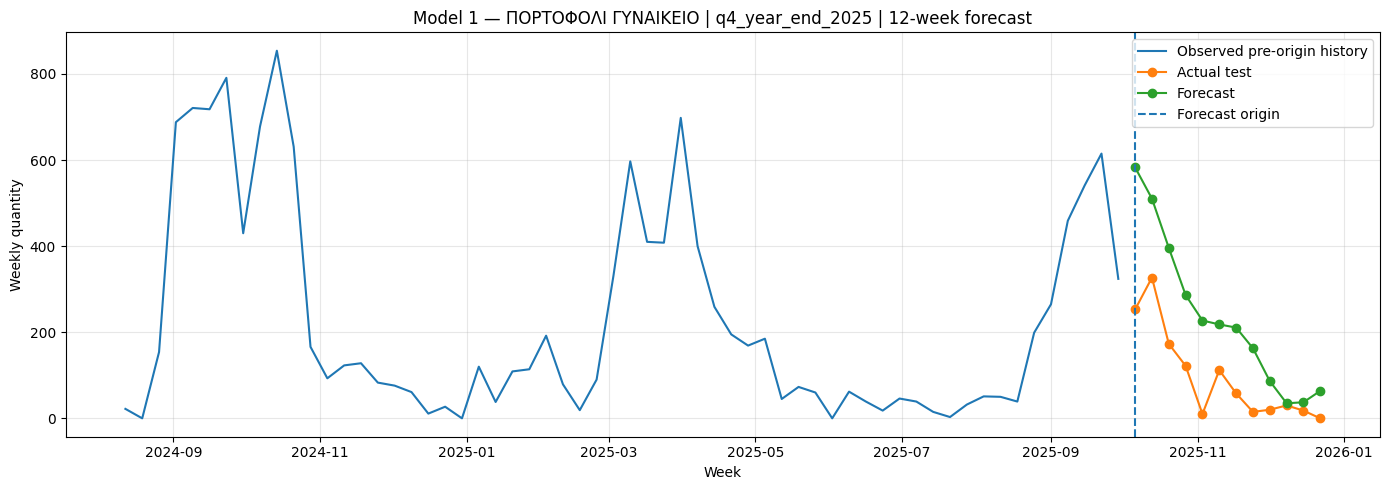

In [26]:
cat_summary=(test_df.groupby("Product Category",as_index=False)
             .agg(mean_MAE=("MAE","mean"),mean_RMSE=("RMSE","mean"),
                  mean_MAPE=("MAPE","mean"),mean_sMAPE=("sMAPE","mean"),
                  mean_MASE=("MASE","mean"),std_MASE=("MASE","std"))
             .sort_values("mean_MASE",ascending=False))
cat_summary.to_csv(OUT_DIR/"model_1_category_error_summary.csv",index=False,encoding="utf-8-sig")
display(cat_summary.head(10))

plt.figure(figsize=(12,7))
w=cat_summary.head(10)
plt.barh(w["Product Category"].astype(str),w.mean_MASE)
plt.xlabel("Mean outer-test MASE"); plt.title("Model 1 — Highest Category-Level MASE")
plt.gca().invert_yaxis(); plt.tight_layout()
plt.savefig(OUT_DIR/"plot_worst_categories_mase.png",dpi=160); plt.show()

plt.figure(figsize=(9,6))
plt.boxplot(cat_summary.mean_MASE.dropna())
plt.ylabel("Mean outer-test MASE"); plt.title("Category-Level MASE Distribution")
plt.tight_layout(); plt.savefig(OUT_DIR/"plot_category_mase_distribution.png",dpi=160); plt.show()

vol=(panel.groupby("Product Category",as_index=False).weekly_quantity.sum()
     .sort_values("weekly_quantity",ascending=False))
top5=vol.head(5)["Product Category"].tolist()

for cat in top5:
    hist=cat_data(cat)
    for label in origin_order:
        f=forecasts_df[(forecasts_df["Product Category"]==cat)&
                       (forecasts_df.outer_origin_label==label)&
                       (forecasts_df.horizon_weeks==12)].copy()
        if f.empty: continue
        origin=pd.Timestamp(f.outer_origin.iloc[0])
        hp=hist[(hist.week_start>=origin-pd.Timedelta(weeks=60))&(hist.week_start<origin)]
        plt.figure(figsize=(14,5))
        plt.plot(hp.week_start,hp.weekly_quantity,label="Observed pre-origin history")
        plt.plot(f.week_start,f.y_true,marker="o",label="Actual test")
        plt.plot(f.week_start,f.y_pred,marker="o",label="Forecast")
        plt.axvline(origin,linestyle="--",label="Forecast origin")
        plt.title(f"Model 1 — {cat} | {label} | 12-week forecast")
        plt.xlabel("Week"); plt.ylabel("Weekly quantity"); plt.legend(); plt.grid(alpha=.3)
        plt.tight_layout()
        safe=str(cat).replace("/","_").replace(" ","_")
        plt.savefig(OUT_DIR/f"plot_forecast_{safe}_{label}_h12.png",dpi=160); plt.show()

In [27]:
log={
    "run_timestamp":datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "model":"Model 1 - Statistical Forecasting Benchmark",
    "input_file":str(INPUT_FILE),
    "outer_origins":OUTER_ORIGINS,
    "forecast_horizons":FORECAST_HORIZONS,
    "inner_cv_horizon":INNER_CV_HORIZON,
    "inner_cv_offsets_weeks":INNER_CV_OFFSETS_WEEKS,
    "seasonal_MASE_m":52,
    "MASE_denominator":"pre-origin in-sample mean absolute seasonal-naive error at lag 52",
    "selection_rule":"lowest mean inner-CV MASE; tie-break: MASE std, RMSE, MAE",
    "metrics":["MAE","RMSE","MAPE(non-zero actuals)","sMAPE","MASE(m=52)"],
    "candidate_count":len(CANDIDATES),
    "candidate_configurations":CANDIDATES,
    "leakage_policy":"Outer-test actuals are used only after forecasts are produced, for scoring.",
    "undefined_MASE_policy":"If the m=52 seasonal-naive in-sample scale is zero/non-finite, MASE is recorded as NaN. No m=1 fallback and no epsilon substitution. Inner model selection then uses sMAPE explicitly as a fallback.",
    "prophet_policy":"Yearly-seasonal Prophet candidates are ineligible in an inner fold with less than 730 calendar days of training history."
}
with open(OUT_DIR/"model_1_experiment_log.json","w",encoding="utf-8") as f:
    json.dump(log,f,indent=2,ensure_ascii=False,default=str)

required=[
    "model_1_inner_cv_all_trials.csv","model_1_selected_configurations.csv",
    "model_1_outer_test_results.csv","model_1_outer_forecasts.csv",
    "model_1_common_rolling_origin_scenarios.csv","model_1_overall_summary.csv",
    "model_1_leakage_audit.csv","model_1_undefined_mase_cases.csv","model_1_experiment_log.json"
]
for name in required:
    p=OUT_DIR/name
    if not p.exists(): raise FileNotFoundError(p)
    print("OK:",name)

print("\nMODEL 1")
print("Outputs:",OUT_DIR)

OK: model_1_inner_cv_all_trials.csv
OK: model_1_selected_configurations.csv
OK: model_1_outer_test_results.csv
OK: model_1_outer_forecasts.csv
OK: model_1_common_rolling_origin_scenarios.csv
OK: model_1_overall_summary.csv
OK: model_1_leakage_audit.csv
OK: model_1_undefined_mase_cases.csv
OK: model_1_experiment_log.json

MODEL 1
Outputs: /content/drive/MyDrive/model_1_rolling_origin_outputs
